<h1 style="color:#003366;">NOVA IMS | MSc in Information Management</h1>
<h2 style="color:#006699;">Data Mining 2025/2026</h2>

<hr style="border:1px solid #006699;">

<h3><b>Group Project:</b> “Why are they not here today?”</h3>
<p><b>Notebook:</b> <i>Data Exploration and Data Preprocessing</i></p>

<h3>Group 16</h3>
<ul>
  <li><b>Beatriz Correia</b> – 20250895</li>
  <li><b>Filipa Brito</b> – 202211807</li>
  <li><b>Rita Silva</b> – 20221920</li>
  <li><b>Rodrigo Conceição</b> – 20220562</li>
</ul>

#### <font color='#006699'>Table of Contents </font> <a class="anchor" id='toc'></a> 
- [0. Imports](#p0)  
- [1. Data Exploration and Understanding](#p1)  
  - [1.1 Overview of the Dataset](#p1-1)  
  - [1.2 Feature Transformation](#p1-2)  
  - [1.3 Visual Exploration](#p1-3)  
- [2. Data Preprocessing](#p2)  
  - [2.1 Handling Missing Values](#p2-1)  
  - [2.2 Incoherences](#p2-2)  
  - [2.3 Outliers](#p2-3)  
- [3. Encoding categorical variables](#p3)  

<h3 style="color:#006699;">0. Imports</h3>

In [67]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from math import ceil
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
from scipy.stats.mstats import winsorize


<font color='#006699' size=6>1. Data Exploration and Understanding</font> <a class="anchor" id="p1"></a>
  
[Back to TOC](#toc)

In [68]:
data_path = os.path.join('data', 'absenteeism_data.csv')
absent_original  = pd.read_csv(data_path, sep=';')
absent = absent_original.copy()
absent.head()

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Days since previous absence,Transportation expense,Distance from Residence to Work,Estimated commute time,Service time,Years until retirement,Date of Birth,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Weight,Height,Body mass index,Absenteeism time in hours
0,11,Unjustified absence,July,Tuesday,Summer,0.0,289,36,69,13,32,1992-08-15,No,1,2,Y,No,1,90,172,30,4
1,36,Unspecified,July,Tuesday,NaN,0.0,118,13,26,18,15,1975-09-02,Yes,1,1,Y,No,0,98,178,31,0
2,3,Medical consultation,July,Wednesday,Summer,0.0,179,51,108,18,27,1987-04-08,No,1,0,Yes,No,0,89,170,31,2
3,7,Diseases of the eye and adnexa,July,Thursday,NaN,0.0,279,5,5,14,26,1986-07-25,No,1,2,Yes,Yes,0,68,168,24,4
4,11,Medical consultation,July,Thursday,Summer,0.0,289,36,69,13,32,1992-08-15,No,1,2,Yes,No,1,90,172,30,2


<h4><b>1.1 Overview of the Dataset</b></h4>
<li>Check basic info: number of rows and columns, column names, and data types.</li>
<li>Check for missing values</li>
<li>Check duplicates</li>

In [69]:
absent.shape

(800, 22)

This dataset has 800 rows and 22 columns.

In [70]:
absent.columns

Index(['ID', 'Reason for absence', 'Month of absence', 'Day of the week',
       'Seasons', 'Days since previous absence', 'Transportation expense',
       'Distance from Residence to Work', 'Estimated commute time',
       'Service time', 'Years until retirement', 'Date of Birth',
       'Disciplinary failure', 'Education', 'Number of children',
       'Social drinker', 'Social smoker', 'Number of pets', 'Weight', 'Height',
       'Body mass index', 'Absenteeism time in hours'],
      dtype='object')

In [71]:
absent.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               800 non-null    int64  
 1   Reason for absence               740 non-null    object 
 2   Month of absence                 737 non-null    object 
 3   Day of the week                  740 non-null    object 
 4   Seasons                          573 non-null    object 
 5   Days since previous absence      781 non-null    float64
 6   Transportation expense           800 non-null    int64  
 7   Distance from Residence to Work  800 non-null    int64  
 8   Estimated commute time           800 non-null    int64  
 9   Service time                     800 non-null    object 
 10  Years until retirement           800 non-null    int64  
 11  Date of Birth                    800 non-null    object 
 12  Disciplinary failure  

As shown, the dataset present some missing values. Specifically, there are missing values in the "Reasons for absence", "Month of absence", "Day of the week", "Seasons", and "Days since previous absence"

In this dataset we have variables of various datatypes. 11 variables are integer, 10 are objects and 1 is float.

In [72]:
absent.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,800.0,17.98500,10.952156,1.0,10.0,18.0,28.0,36.0
Days since previous absence,781.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.0
Transportation expense,800.0,221.92750,66.778732,118.0,179.0,225.0,260.0,388.0
Distance from Residence to Work,800.0,29.79875,14.875057,5.0,16.0,26.0,50.0,52.0
Estimated commute time,800.0,59.34875,31.301067,5.0,31.0,52.0,94.0,114.0
Years until retirement,800.0,26.74250,9.269498,-1.0,25.0,28.0,33.0,38.0
Education,800.0,1.28750,0.667383,1.0,1.0,1.0,1.0,4.0
Number of children,800.0,1.04375,1.120672,0.0,0.0,1.0,2.0,4.0
Number of pets,800.0,0.74500,1.323694,0.0,0.0,0.0,1.0,8.0
Height,800.0,172.09375,6.058122,163.0,169.0,170.0,172.0,196.0


In [73]:
# Summary statistics for categorical columns
absent.describe(include = ['O'])

,Reason for absence,Month of absence,Day of the week,Seasons,Service time,Date of Birth,Disciplinary failure,Social drinker,Social smoker,Weight
count,740,737,740,573,800,800,800,800,800,800
unique,28,12,6,4,19,36,2,3,3,27
top,Medical consultation,March,Monday,Spring,18,1987-04-08,No,Yes,No,89
freq,149,87,159,155,150,122,756,367,744,110


In [74]:
absent.isnull().sum()

ID                                   0
Reason for absence                  60
Month of absence                    63
Day of the week                     60
Seasons                            227
Days since previous absence         19
Transportation expense               0
Distance from Residence to Work      0
Estimated commute time               0
Service time                         0
Years until retirement               0
Date of Birth                        0
Disciplinary failure                 0
Education                            0
Number of children                   0
Social drinker                       0
Social smoker                        0
Number of pets                       0
Weight                               0
Height                               0
Body mass index                      0
Absenteeism time in hours            0
dtype: int64

This dataset has missing values in the columns 'Reason for absence' (60), 'Month of absence' (63), 'Day of the week' (60), 'Seasons' (227) and 'Days since previous absence' (19).

In [75]:
round(absent.isna().sum()/len(absent)*100,2)

ID                                  0.00
Reason for absence                  7.50
Month of absence                    7.88
Day of the week                     7.50
Seasons                            28.38
Days since previous absence         2.38
Transportation expense              0.00
Distance from Residence to Work     0.00
Estimated commute time              0.00
Service time                        0.00
Years until retirement              0.00
Date of Birth                       0.00
Disciplinary failure                0.00
Education                           0.00
Number of children                  0.00
Social drinker                      0.00
Social smoker                       0.00
Number of pets                      0.00
Weight                              0.00
Height                              0.00
Body mass index                     0.00
Absenteeism time in hours           0.00
dtype: float64

In [76]:
absent.duplicated().sum()

26

In [77]:
absent = absent.drop_duplicates()

In [78]:
# Inspecting unique values per column to detect inconsistencies
for col in absent.columns:
    print(f"--- {col} ---")
    print(absent[col].unique())
    print()

--- ID ---
[11 36  3  7 10 20 14  1 24  6 33 18 30  2 19 27 34  5 15 29 28 13 22 17
 31 23 32  9 26 21  8 25 12 16  4 35]

--- Reason for absence ---
['Unjustified absence' 'Unspecified' 'Medical consultation'
 'Diseases of the eye and adnexa' 'Patient follow-up'
 'Injury, poisoning and other consequences of external causes'
 'Certain infectious and parasitic diseases' nan
 'Diseases of the digestive system' 'Diseases of the genitourinary system'
 'Factors influencing health status and contact with health services'
 'Diseases of the respiratory system'
 'Diseases of the musculoskeletal system and connective tissue'
 'Dental consultation'
 'Symptoms, signs and abnormal clinical and laboratory findings'
 'Laboratory examination' 'Blood donation'
 'Diseases of the nervous system' 'Physiotherapy'
 'Congenital malformations, deformations and chromosomal abnormalities'
 'Diseases of the ear and mastoid process'
 'Diseases of the skin and subcutaneous tissue'
 'Mental and behavioural disorder

<h4><b>1.2 Feature Transformation</b></h4>

We will convert "Data of Birth" in "Age" and drop original date to obtain a more relevant and interpretable numeric variable

In [79]:
absent['Date of Birth'] = pd.to_datetime(absent['Date of Birth'])
absent['Age'] = 2025 - absent['Date of Birth'].dt.year
absent.drop(columns=['Date of Birth'], inplace=True)
absent.head(5)

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Days since previous absence,Transportation expense,Distance from Residence to Work,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Weight,Height,Body mass index,Absenteeism time in hours,Age
0,11,Unjustified absence,July,Tuesday,Summer,0.0,289,36,69,13,32,No,1,2,Y,No,1,90,172,30,4,33
1,36,Unspecified,July,Tuesday,NaN,0.0,118,13,26,18,15,Yes,1,1,Y,No,0,98,178,31,0,50
2,3,Medical consultation,July,Wednesday,Summer,0.0,179,51,108,18,27,No,1,0,Yes,No,0,89,170,31,2,38
3,7,Diseases of the eye and adnexa,July,Thursday,NaN,0.0,279,5,5,14,26,No,1,2,Yes,Yes,0,68,168,24,4,39
4,11,Medical consultation,July,Thursday,Summer,0.0,289,36,69,13,32,No,1,2,Yes,No,1,90,172,30,2,33


In [80]:
absent.dtypes


ID                                   int64
Reason for absence                  object
Month of absence                    object
Day of the week                     object
Seasons                             object
Days since previous absence        float64
Transportation expense               int64
Distance from Residence to Work      int64
Estimated commute time               int64
Service time                        object
Years until retirement               int64
Disciplinary failure                object
Education                            int64
Number of children                   int64
Social drinker                      object
Social smoker                       object
Number of pets                       int64
Weight                              object
Height                               int64
Body mass index                      int64
Absenteeism time in hours            int64
Age                                  int64
dtype: object

In [81]:
cols_to_convert = [
    'Service time',
    'Weight',
    'Days since previous absence'
]

for col in cols_to_convert:
    absent[col] = pd.to_numeric(absent[col], errors='coerce').astype('Int64')


We observed that "Service time" and "Weight" were originally stored as object types, while "Days since previous absence" had a float64 type. To ensure consistency and facilitate further analysis, we converted all three variables to the Int64 data type.

In [82]:
absent.isnull().sum()

ID                                   0
Reason for absence                  52
Month of absence                    55
Day of the week                     52
Seasons                            217
Days since previous absence         19
Transportation expense               0
Distance from Residence to Work      0
Estimated commute time               0
Service time                        28
Years until retirement               0
Disciplinary failure                 0
Education                            0
Number of children                   0
Social drinker                       0
Social smoker                        0
Number of pets                       0
Weight                              77
Height                               0
Body mass index                      0
Absenteeism time in hours            0
Age                                  0
dtype: int64

Since we changed the datatype of some variables to Int64, that were set as objects, these same variables have started showing missing values. This is the case of "Weight", and "Service Time"

<h4><b>1.3 Visual Exploration</b></h4>

<b>1.3.1 Explore Categorical Variables</b>

- For categorical variables we will:
  - Show value counts
  - Show count plots (ordered where meaningful)
- This helps identify inconsistent values (e.g., 'Y' vs 'Yes') and rare categories.

Medical consultation                                                    146
Dental consultation                                                     109
Physiotherapy                                                            60
Diseases of the musculoskeletal system and connective tissue             55
Unspecified                                                              43
Injury, poisoning and other consequences of external causes              40
Patient follow-up                                                        36
Unjustified absence                                                      33
Laboratory examination                                                   30
Diseases of the digestive system                                         26
Diseases of the respiratory system                                       25
Symptoms, signs and abnormal clinical and laboratory findings            21
Diseases of the genitourinary system                                     19
Certain infe

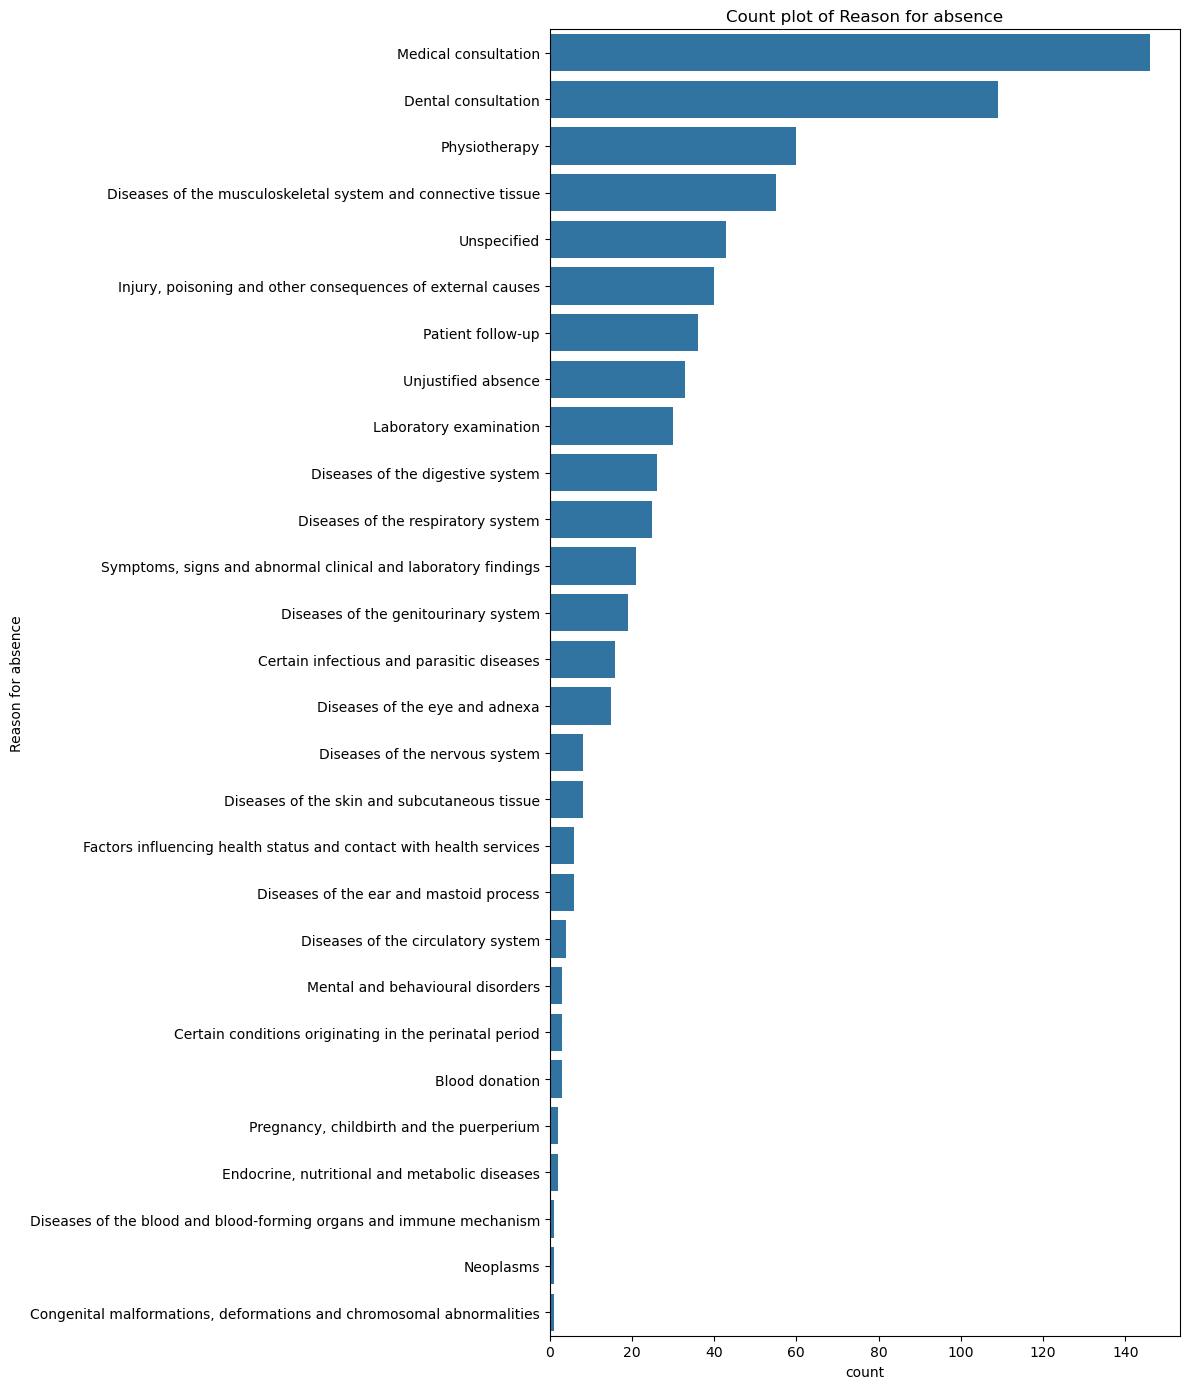

March        85
October      69
February     69
July         66
November     63
May          62
August       54
June         53
September    52
April        51
January      48
December     47
Name: Month of absence, dtype: int64


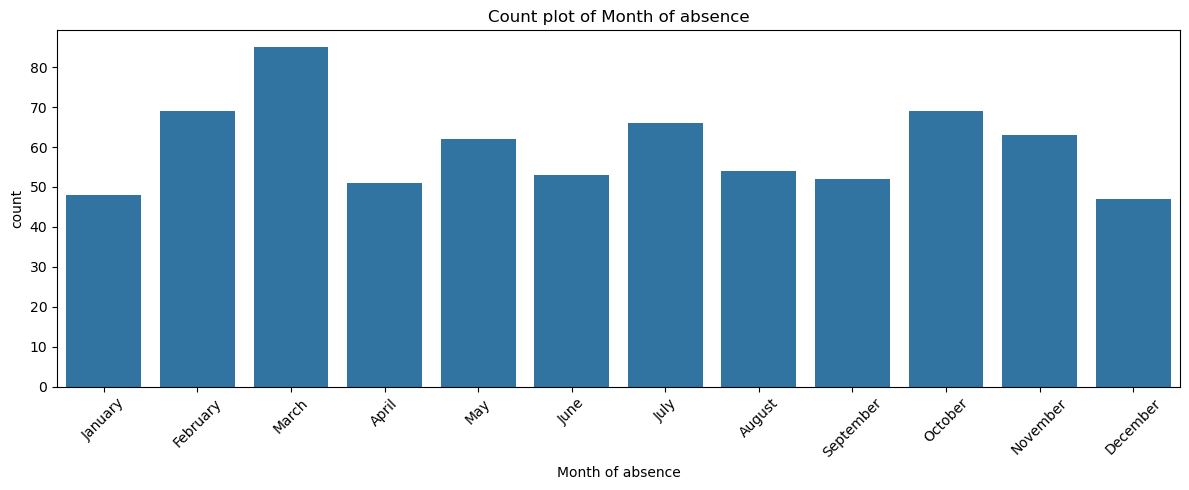

Monday       157
Wednesday    150
Tuesday      148
Friday       139
Thursday     122
Saturday       6
Name: Day of the week, dtype: int64


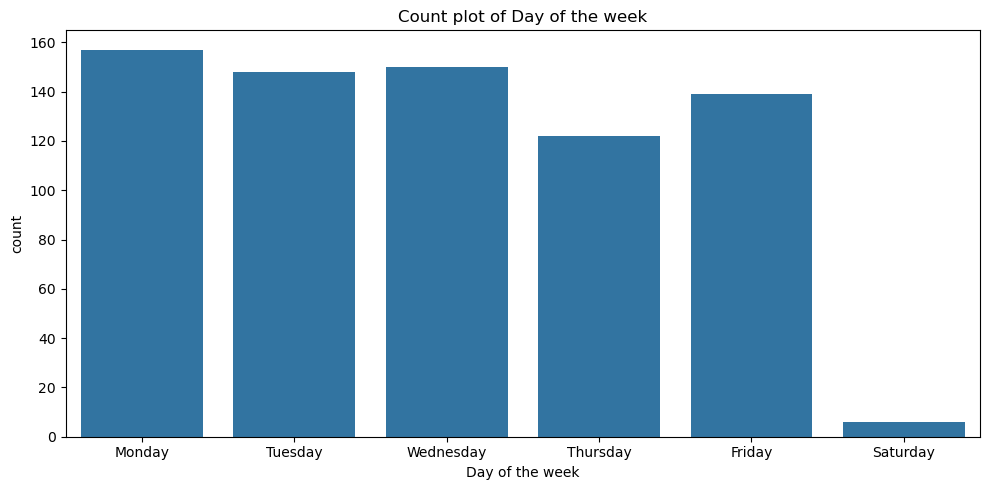

Spring    152
Autumn    142
Winter    137
Summer    126
Name: Seasons, dtype: int64


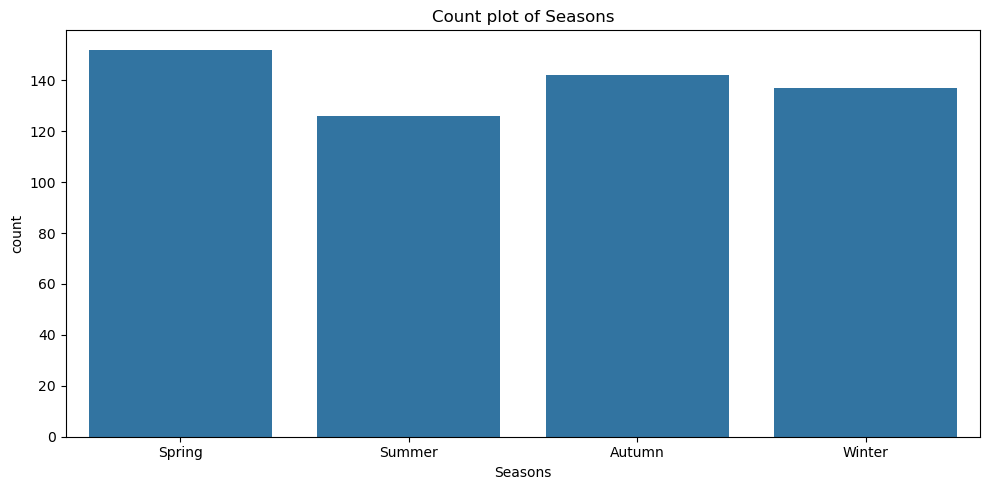

No     730
Yes     44
Name: Disciplinary failure, dtype: int64


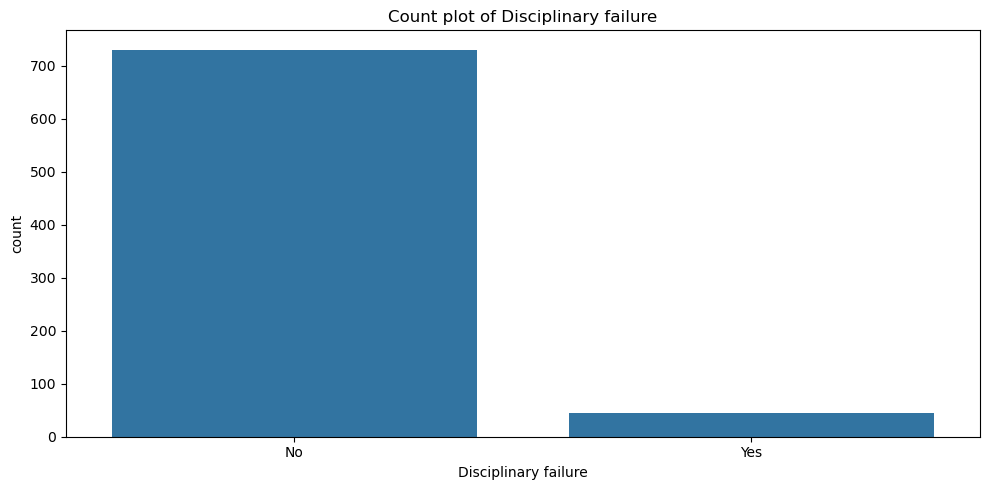

1    641
3     79
2     50
4      4
Name: Education, dtype: int64


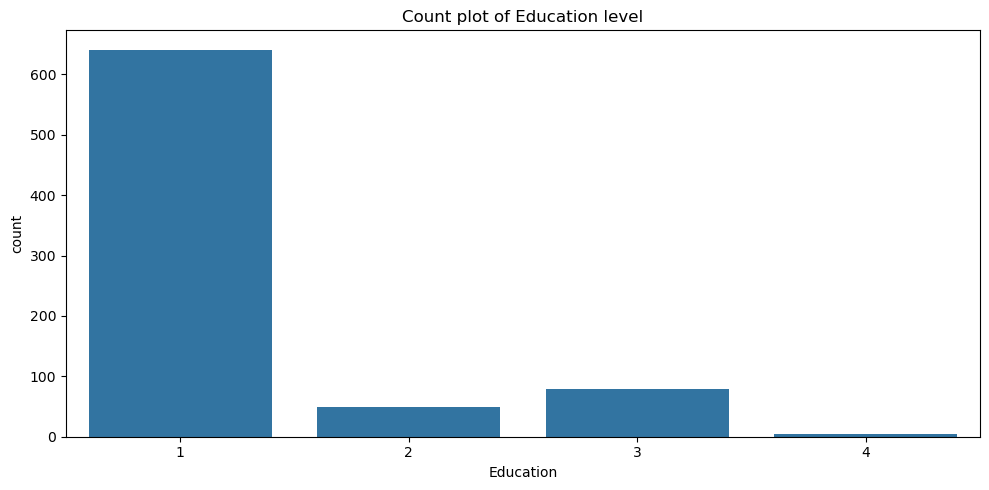

No     719
Yes     53
Y        2
Name: Social smoker, dtype: int64


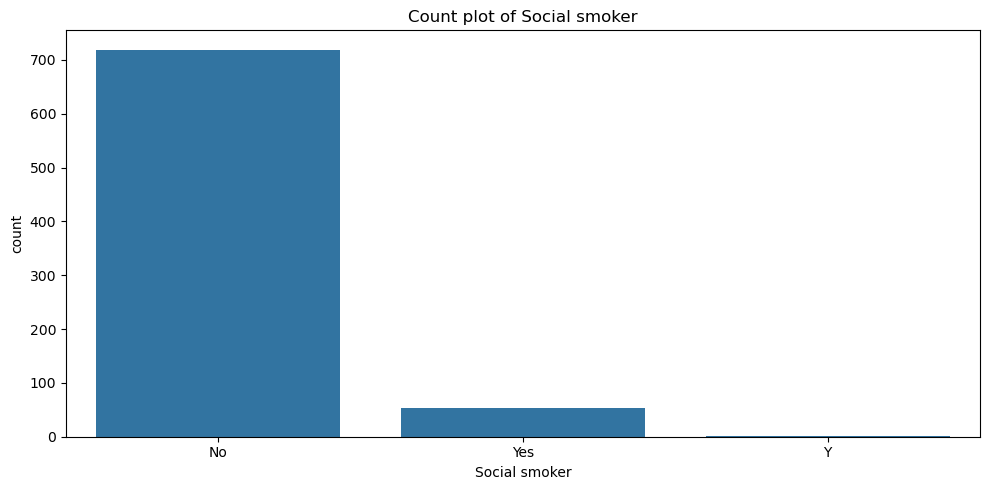

Yes    355
No     329
Y       90
Name: Social drinker, dtype: int64


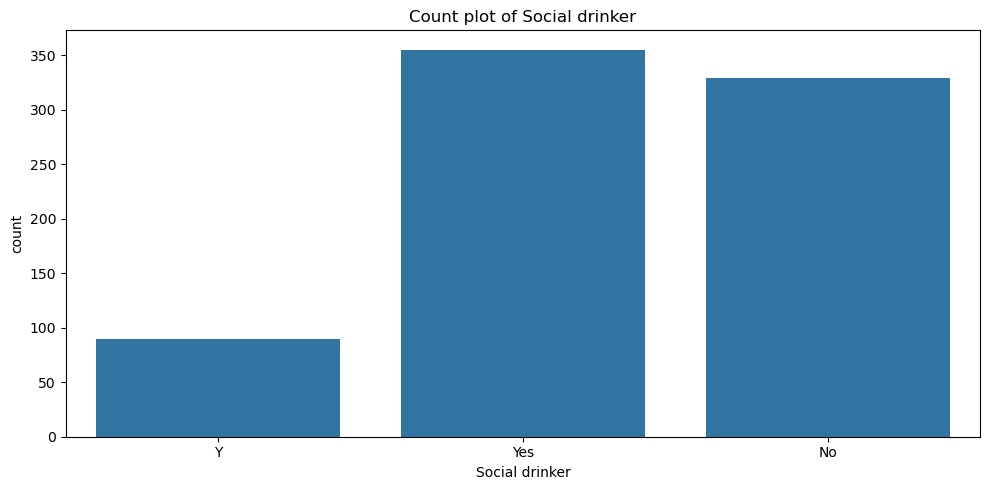

In [83]:
categorical_cols = [
    'Reason for absence', 
    'Month of absence', 
    'Day of the week', 
    'Seasons', 
    'Disciplinary failure', 
    'Education',
    'Social smoker',
    'Social drinker'
]

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']
education_order = [1, 2, 3, 4]

# Loop through each categorical feature to inspect its distribution
# and visualize potential patterns or irregularities
for col in categorical_cols:
    print(absent[col].value_counts())

    if col == 'Reason for absence':
        plt.figure(figsize=(12, 14))
        order = absent[col].value_counts().index
        sns.countplot(data=absent, y=col, order=order)
        plt.title('Count plot of Reason for absence')
        plt.tight_layout()
        plt.show()

    elif col == 'Month of absence':
        plt.figure(figsize=(12, 5))
        sns.countplot(data=absent, x=col, order=month_order)
        plt.xticks(rotation=45)
        plt.title('Count plot of Month of absence')
        plt.tight_layout()
        plt.show()

    elif col == 'Day of the week':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col, order=day_order)
        plt.title('Count plot of Day of the week')
        plt.tight_layout()
        plt.show()

    elif col == 'Seasons':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col, order=season_order)
        plt.title('Count plot of Seasons')
        plt.tight_layout()
        plt.show()

    elif col == 'Education':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col, order=education_order)
        plt.title('Count plot of Education level')
        plt.tight_layout()
        plt.show()

    elif col == 'Social drinker':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col)
        plt.title('Count plot of Social drinker')
        plt.tight_layout()
        plt.show()

    elif col == 'Social smoker':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col)
        plt.title('Count plot of Social smoker')
        plt.tight_layout()
        plt.show()

    elif col == 'Disciplinary failure':
        plt.figure(figsize=(10,5))
        sns.countplot(data=absent, x=col)
        plt.title('Count plot of Disciplinary failure')
        plt.tight_layout()
        plt.show()




We examined all categorical variables using value counts and ordered count plots. This step highlighted several issues:
- Inconsistent labels (e.g. "Y" vs. "Yes)
- Presence of "Saturday" and the compay only operate from Monday to Friday
- Missing values in key temporal fields

<b>1.3.2 Explore Numerical Variables</b>

1. Histograms — understanding distributions

In [84]:
numeric_cols = [
    'Transportation expense',
    'Distance from Residence to Work',
    'Estimated commute time',
    'Service time',
    'Years until retirement',
    'Weight',
    'Height',
    'Body mass index',
    'Absenteeism time in hours',
    'Number of children',
    'Number of pets',
    'Age'
]

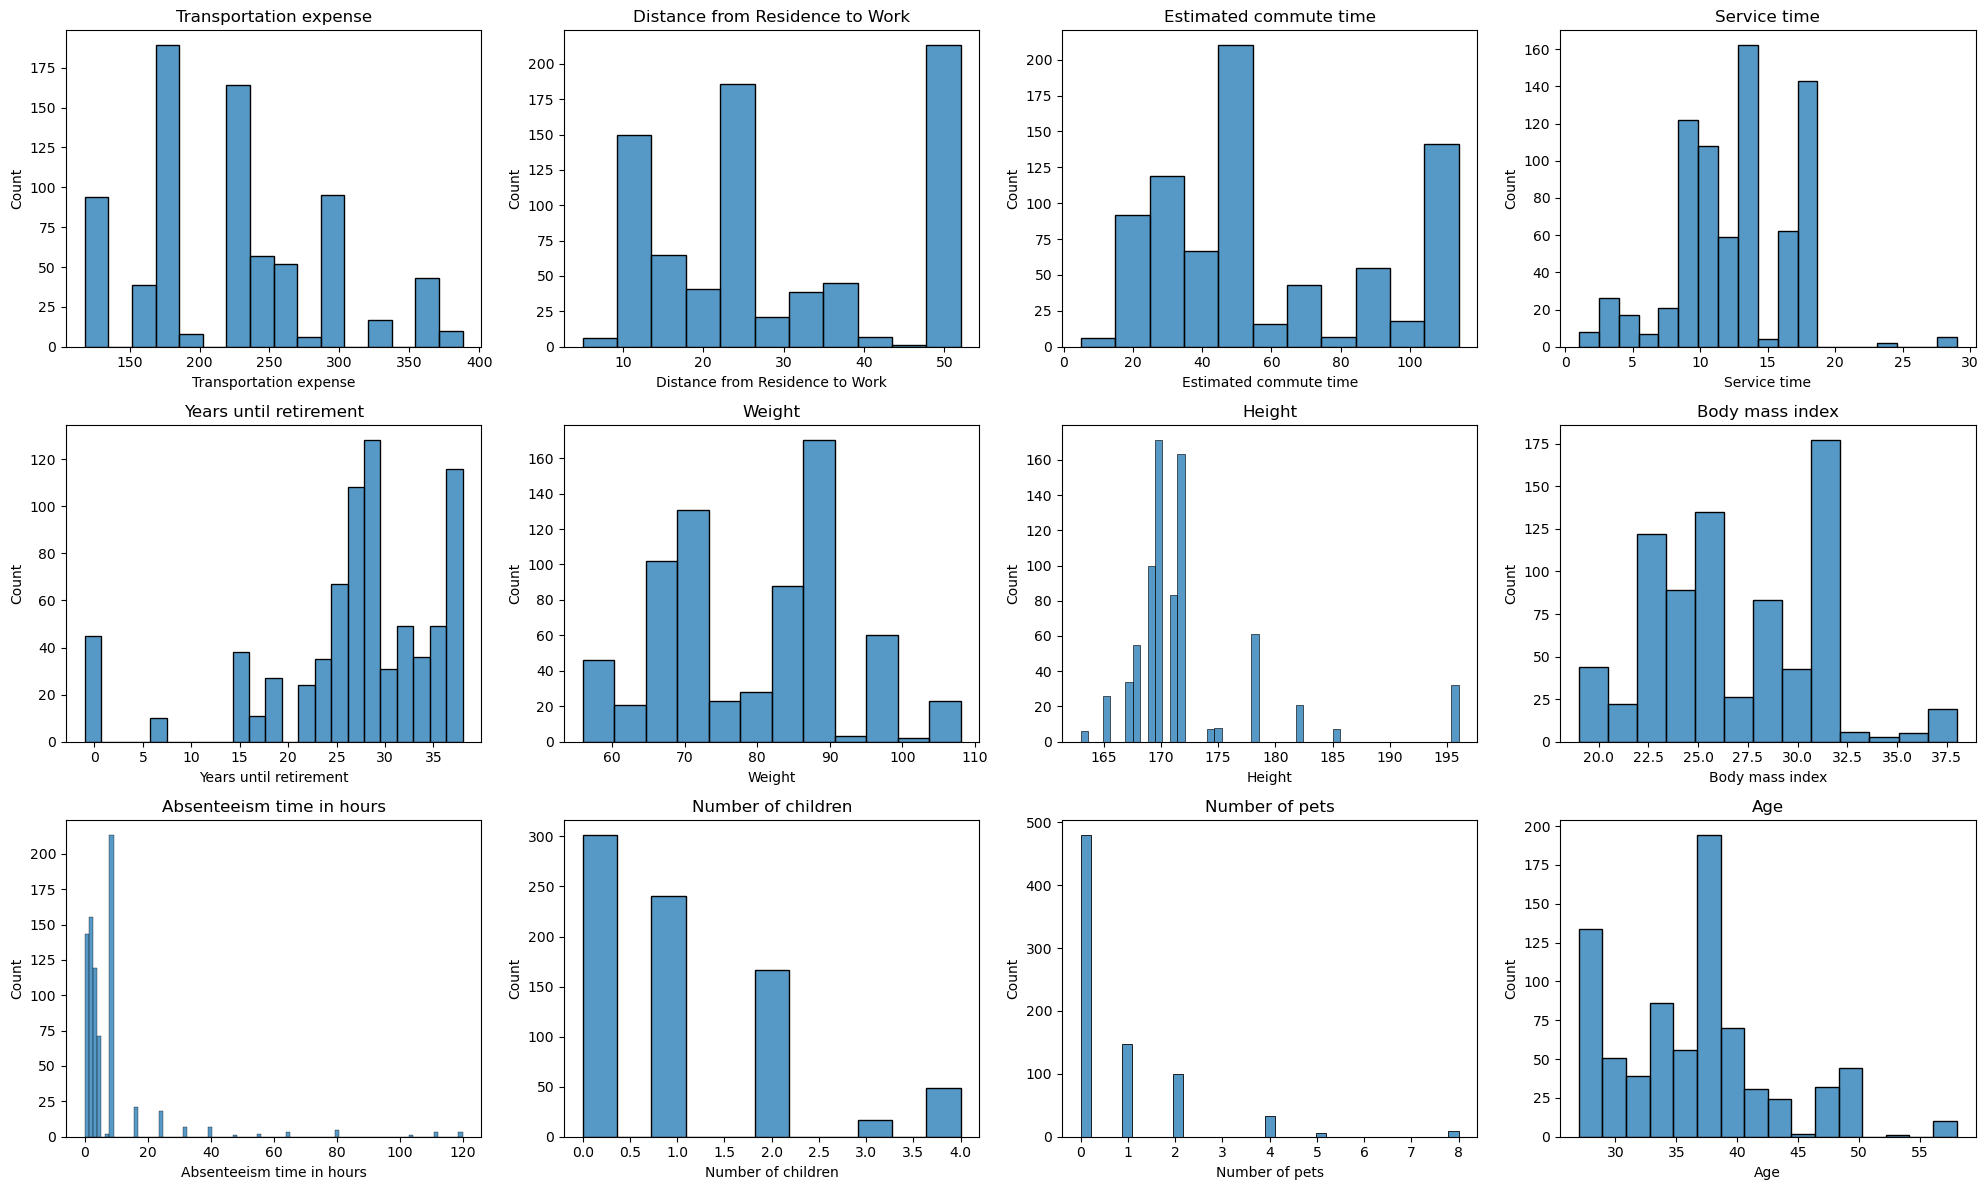

In [85]:
plt.figure(figsize=(20, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(ceil(len(numeric_cols) / 4), 4, i)
    sns.histplot(absent[col].dropna(), kde=False)  
    plt.title(col)

plt.tight_layout()
plt.show()


The histograms revealed that several variables present rigth-skewed distributions, including "Transportation expenses" and "Absenteeims time in hours".

In [86]:
# Ensuring all numeric columns are truly numeric.
for col in numeric_cols:
    absent[col] = pd.to_numeric(absent[col], errors='coerce').astype(float)


2. Boxplots — detecting outliers visually

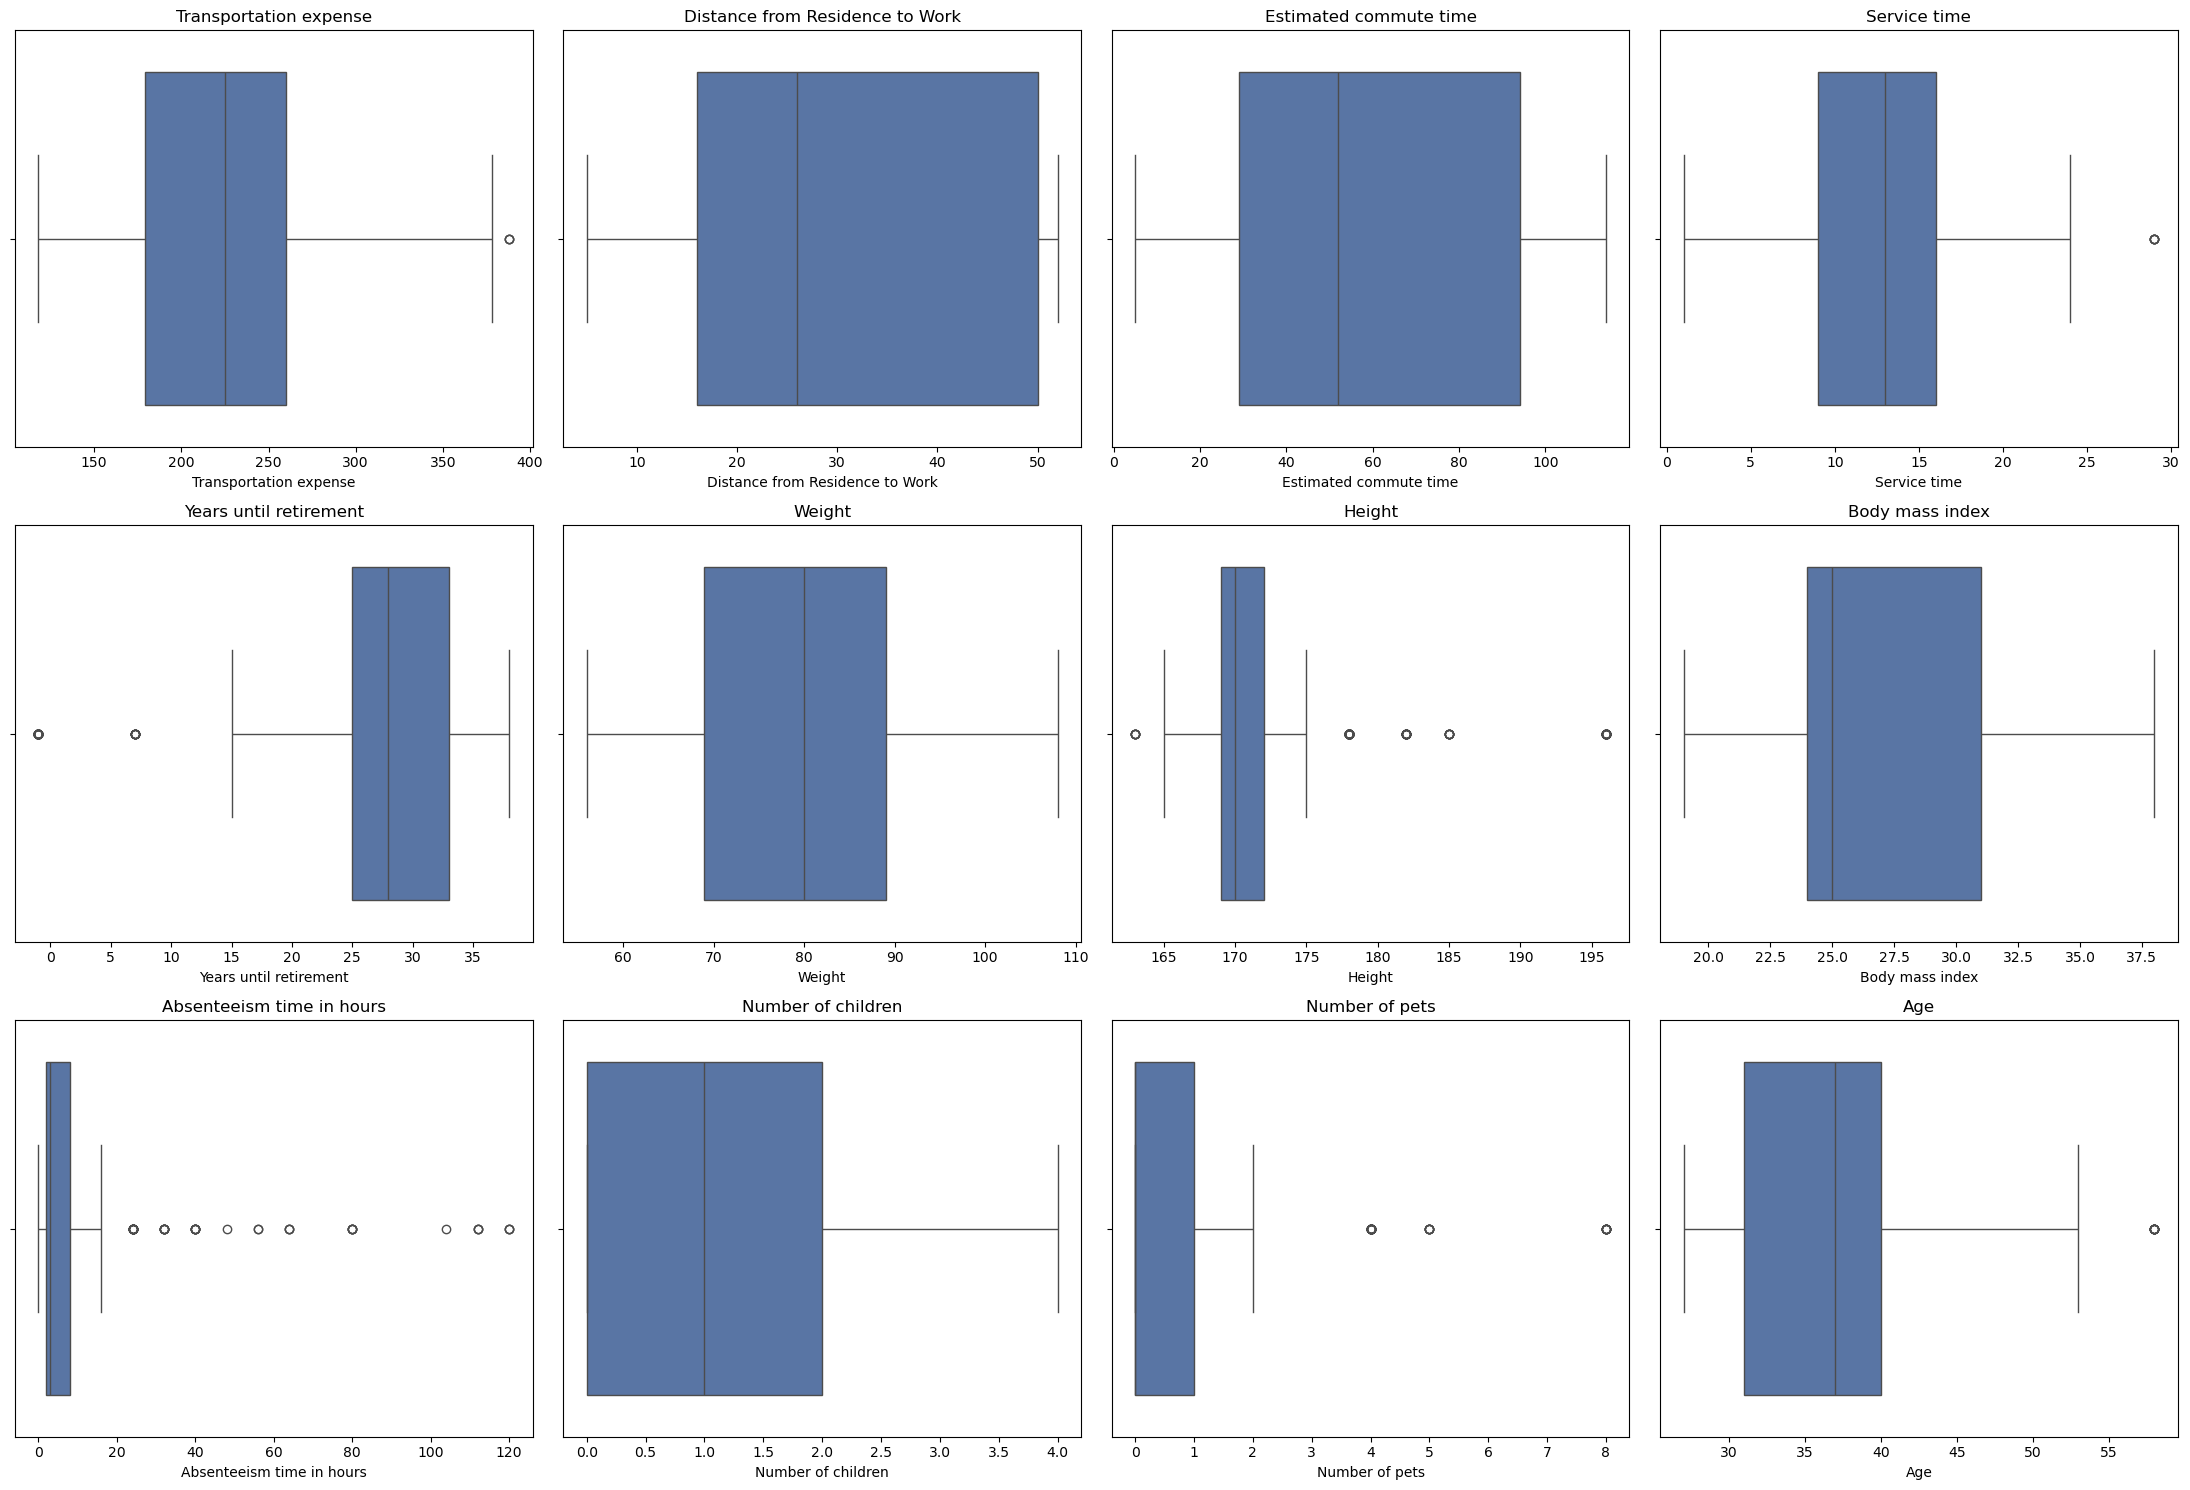

In [87]:
# Boxplots for visual identification of outliers.
plt.figure(figsize=(22, 15))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(ceil(len(numeric_cols) / 4), 4, i)
    sns.boxplot(x=absent[col], color="#4C72B0")
    plt.title(col)
    plt.tight_layout()

plt.show()


The boxplots highlighted clear outliers in variables such as "Transportation expenses", "Years until retirement" and "Absenteeims time in hours". 

3. Relationship with Education

C:\Users\ritam\AppData\Local\Temp\ipykernel_23632\825046830.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=absent, x='Education', y=col, palette="Set2")
C:\Users\ritam\AppData\Local\Temp\ipykernel_23632\825046830.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=absent, x='Education', y=col, palette="Set2")
C:\Users\ritam\AppData\Local\Temp\ipykernel_23632\825046830.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=absent, x='Education', y=col, palette="Set2")
C:\Users\ritam\AppData\Local\Temp\ipykernel_23632\82504683

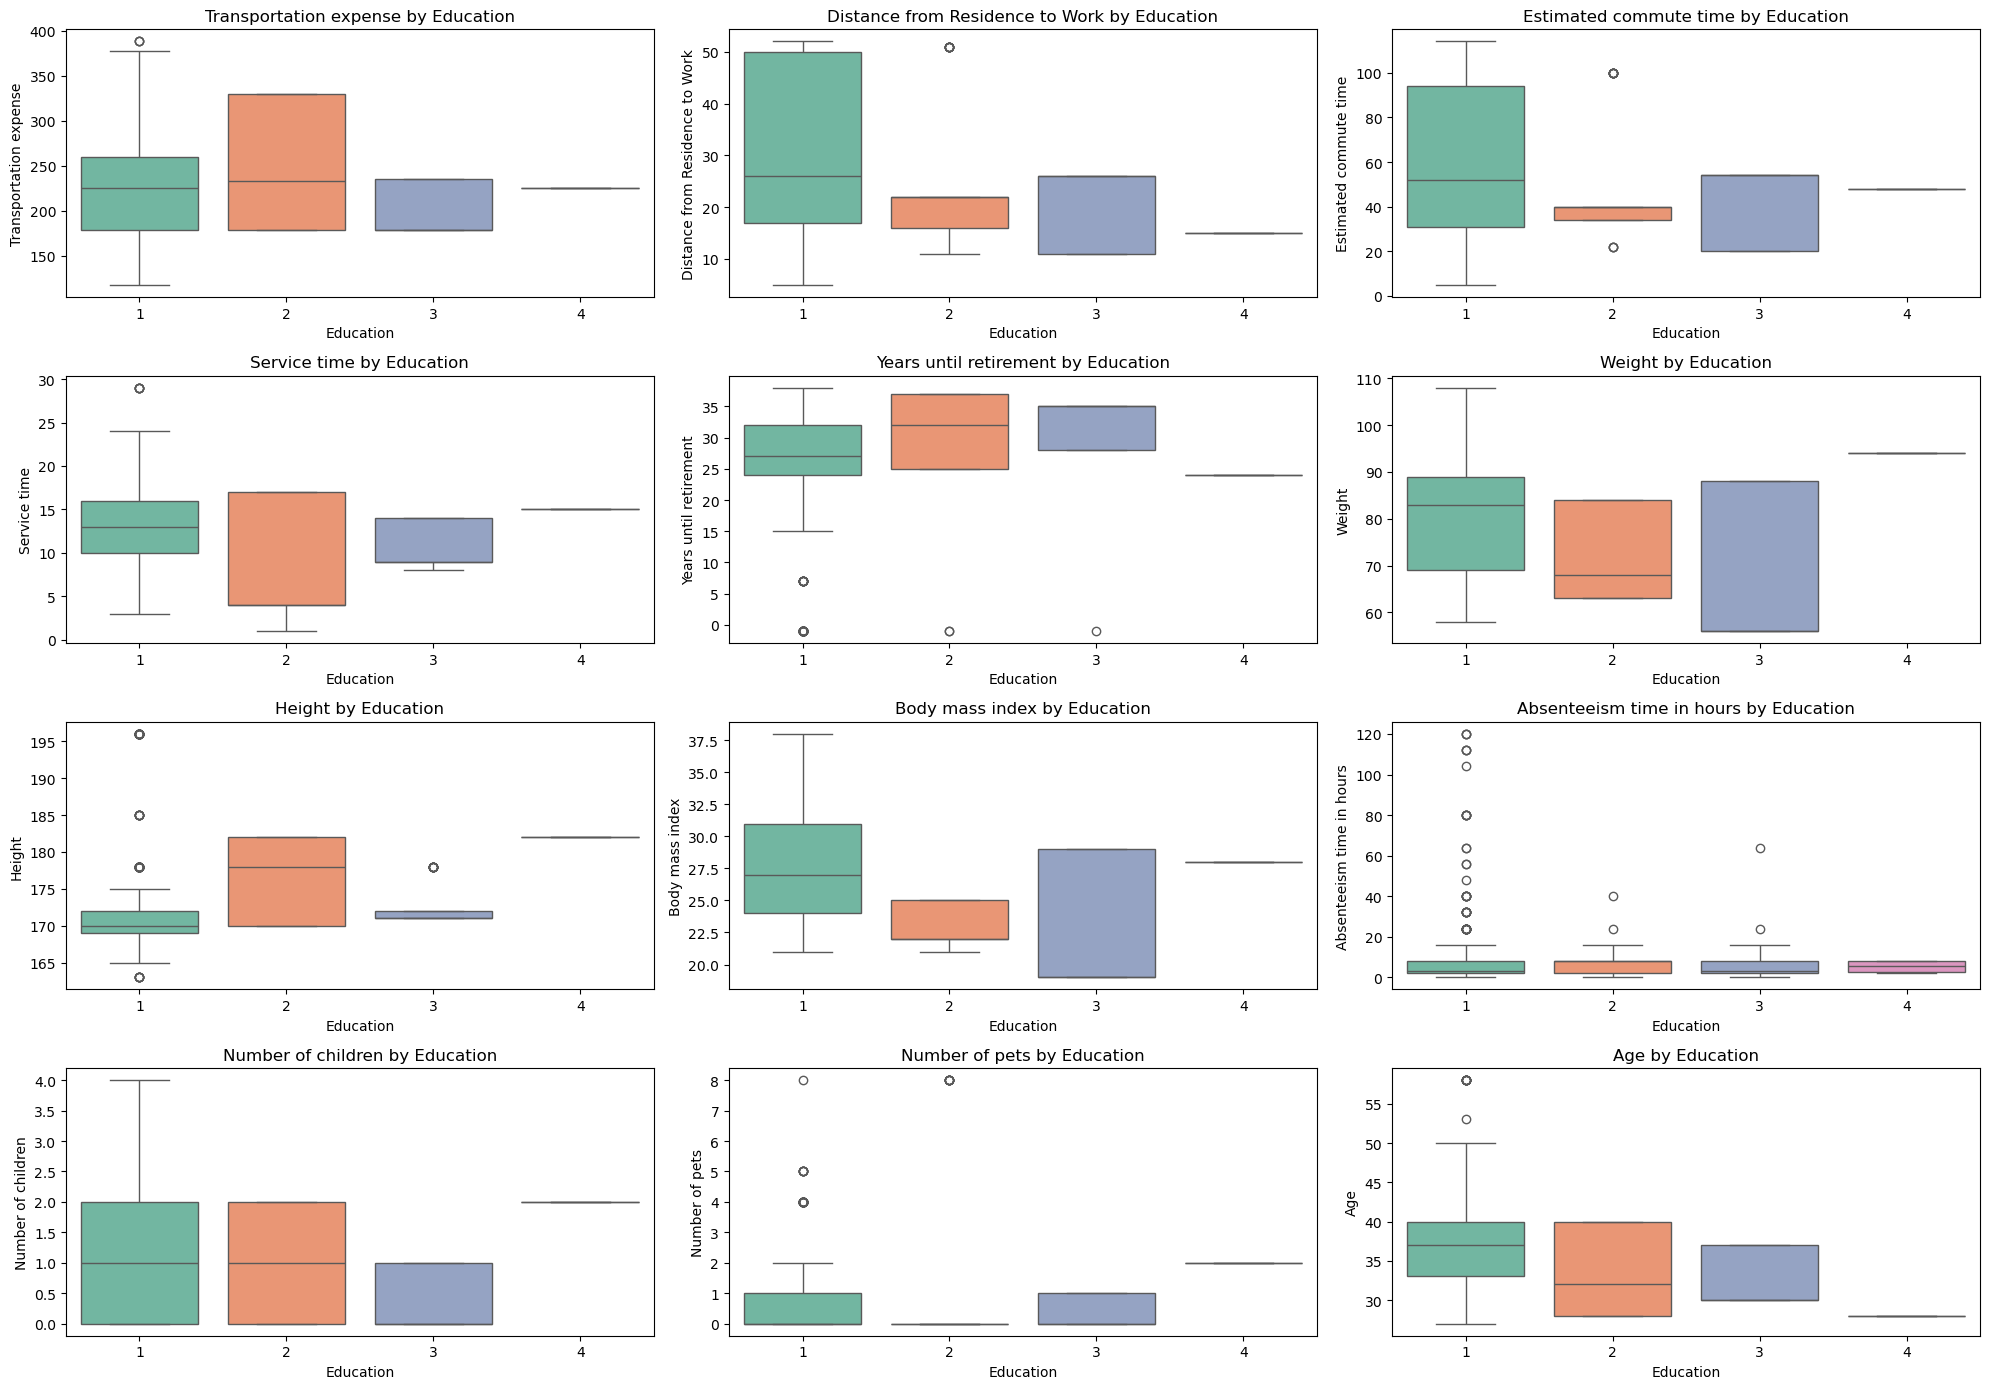

In [88]:
# Relationship between numeric variables and education levels.
plt.figure(figsize=(20, 14))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(ceil(len(numeric_cols)/3), 3, i)
    sns.boxplot(data=absent, x='Education', y=col, palette="Set2")
    plt.title(f'{col} by Education')
    plt.tight_layout()

plt.show()


4. Co-occurrence sorted by frequency

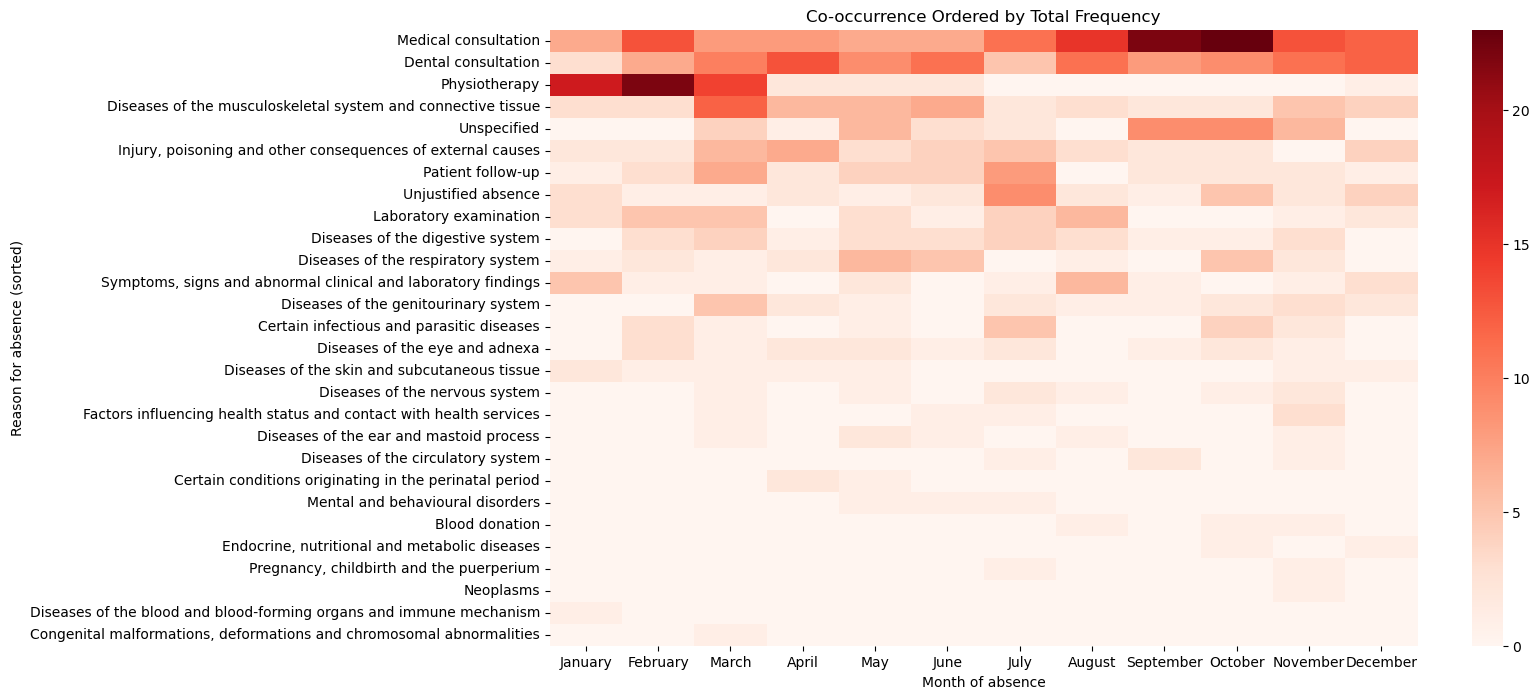

In [89]:
cooc = pd.crosstab(absent['Reason for absence'], absent['Month of absence'])

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

cooc_sorted = cooc.loc[
    cooc.sum(axis=1).sort_values(ascending=False).index,
    month_order
]

plt.figure(figsize=(14, 8))
sns.heatmap(cooc_sorted, cmap="Reds", annot=False)
plt.title("Co-occurrence Ordered by Total Frequency")
plt.xlabel("Month of absence")
plt.ylabel("Reason for absence (sorted)")
plt.show()

Additionally, we generated a co-occurrence heatmap between Reason for absence and Month of absence, concluding that some medical-related absences peak during winter months.

6. Scatterplot Distance vs Commute Time

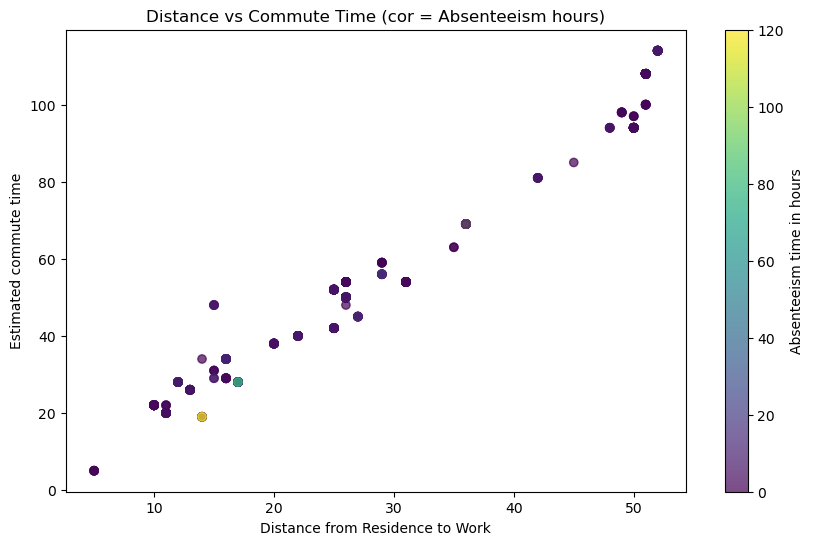

In [90]:
plt.figure(figsize=(10, 6))
plt.scatter(
    absent['Distance from Residence to Work'],
    absent['Estimated commute time'],
    c=absent['Absenteeism time in hours'],
    alpha=0.7
)
plt.colorbar(label='Absenteeism time in hours')
plt.xlabel("Distance from Residence to Work")
plt.ylabel("Estimated commute time")
plt.title("Distance vs Commute Time (cor = Absenteeism hours)")
plt.show()


The scatterplot reveal that commute time has a strongly correlation with distance from residence to work, but does not show any visible relationship with absenteeism hours.

7. Absenteeism vs Number of Children

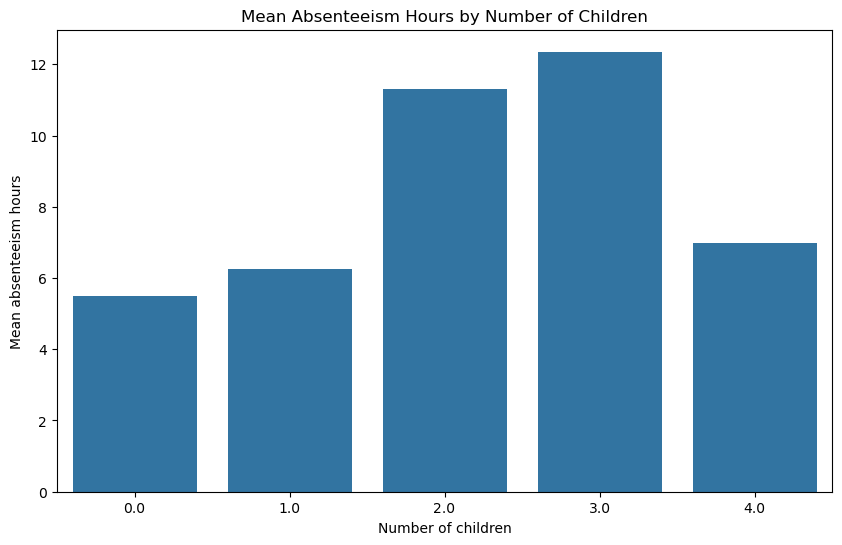

In [91]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=absent,
    x='Number of children',
    y='Absenteeism time in hours',
    estimator='mean',
    errorbar=None
)
plt.title("Mean Absenteeism Hours by Number of Children")
plt.ylabel("Mean absenteeism hours")
plt.show()


8. Mean Absenteeism by Reason

C:\Users\ritam\AppData\Local\Temp\ipykernel_23632\223084624.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


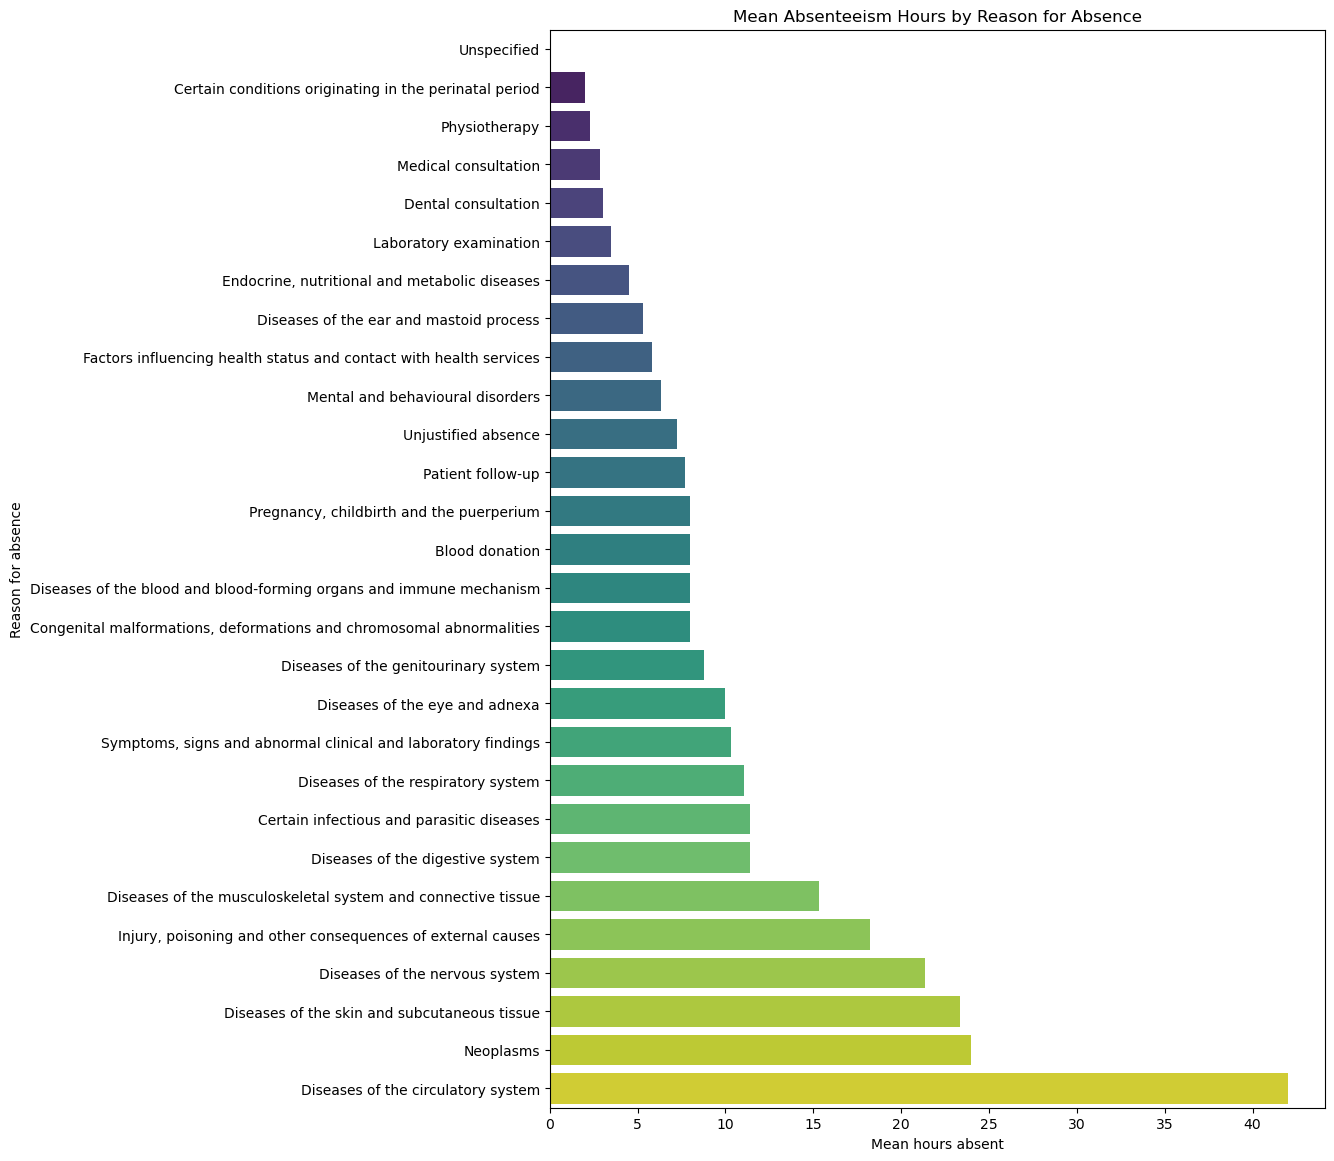

In [92]:
plt.figure(figsize=(10, 14))

mean_hours = (
    absent.groupby('Reason for absence')['Absenteeism time in hours']
    .mean()
    .sort_values()
)

sns.barplot(
    x=mean_hours.values,
    y=mean_hours.index,
    orient="h",
    palette="viridis"
)

plt.title("Mean Absenteeism Hours by Reason for Absence")
plt.xlabel("Mean hours absent")
plt.ylabel("Reason for absence")
plt.show()


<b>1.3.3 Correlation analysis</b>

<u>Pearson correlation matrix</u>

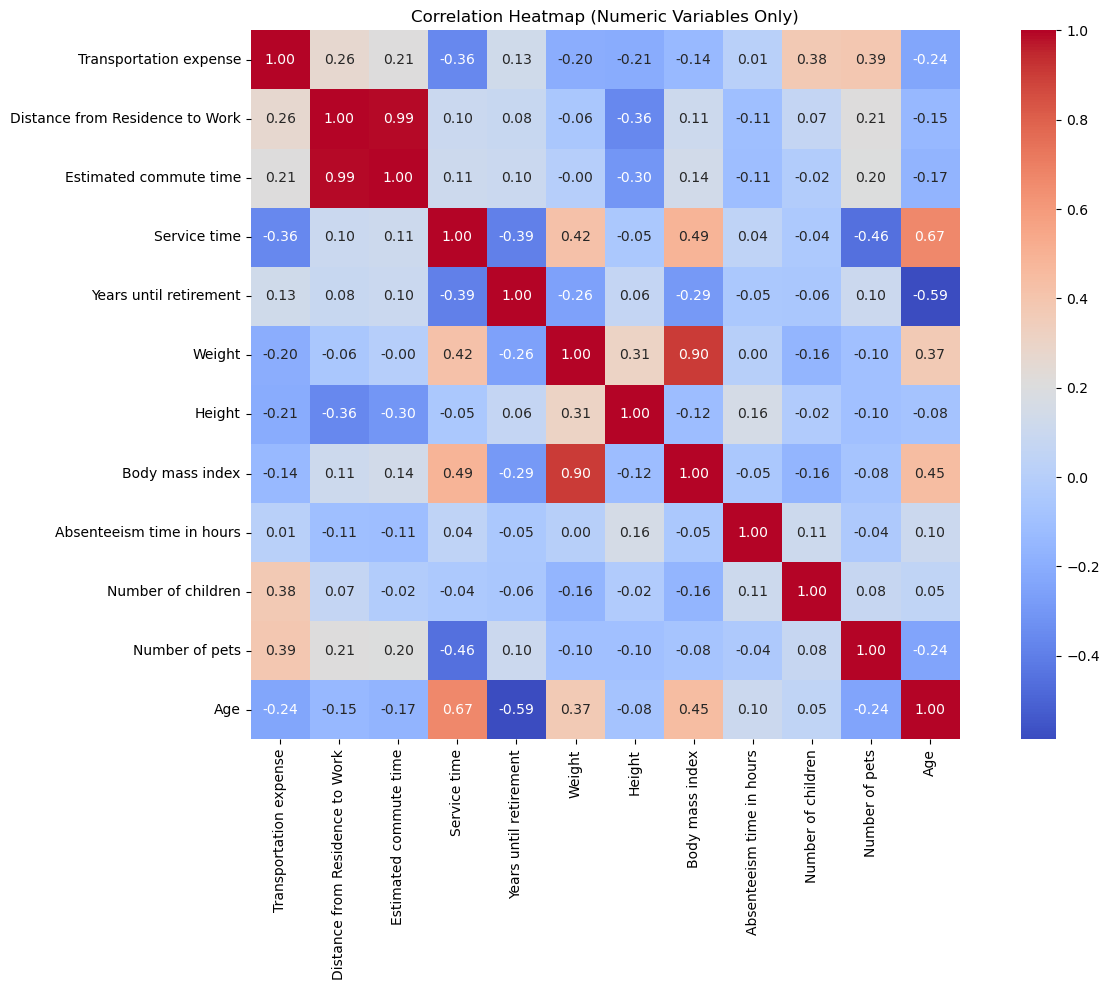

In [93]:
numeric_valid = [
    'Transportation expense',
    'Distance from Residence to Work',
    'Estimated commute time',
    'Service time',
    'Years until retirement',
    'Weight',
    'Height',
    'Body mass index',
    'Absenteeism time in hours',
    'Number of children',
    'Number of pets',
    'Age',
]

# Computing Pearson correlation matrix for numerical variables.
corr_matrix = absent[numeric_valid].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm",
    square=True
)
plt.title("Correlation Heatmap (Numeric Variables Only)")
plt.tight_layout()
plt.show()


For the numerical features, we computed a Pearson correlation matrix. The heatmap revelead several strong relationships:
- "Weight" and "Body mass index" form a highly correlated due, meaning they carry overlapping information.
- "Estimated commute time" and "Distance from Residence to Work" also dispaly strong correlation, indicating redundancy in commuting-related attributes.
- "Age" and "Years until retirement" naturally show a strong negative relationship due to their structural dependecy.

<u>Cramér's V for categorical variables</u>

Cramér's V Matrix:


,Reason for absence,Month of absence,Day of the week,Seasons
Reason for absence,1.000000,0.261962,0.202769,0.350365
Month of absence,0.261962,1.000000,0.126359,0.907933
Day of the week,0.202769,0.126359,1.000000,0.127340
Seasons,0.350365,0.907933,0.127340,1.000000


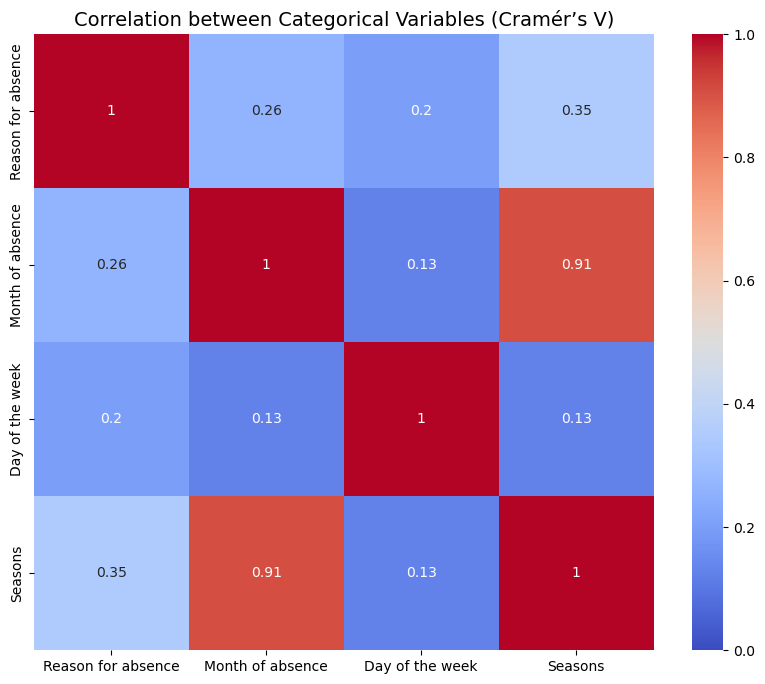

In [94]:
# Function to compute Cramér’s V between two categorical variables.
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.empty:
        return np.nan
    chi2 = chi2_contingency(table)[0]
    n = table.sum().sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cat_cols = [
    'Reason for absence',
    'Month of absence',
    'Day of the week',
    'Seasons'
]

# Building the Cramér’s V matrix.
cramer_matrix = pd.DataFrame(
    np.zeros((len(cat_cols), len(cat_cols))),
    index=cat_cols,
    columns=cat_cols
)

for col1 in cat_cols:
    for col2 in cat_cols:
        cramer_matrix.loc[col1, col2] = cramers_v(absent[col1], absent[col2])

print("Cramér's V Matrix:")
display(cramer_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(cramer_matrix, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation between Categorical Variables (Cramér’s V)", fontsize=14)
plt.show()


We computed Cramér's V, which measures strength between categorical variables (0 = no association, 1 = perfect association). The resulting matrix showed moderated associations between:
- "Month of absence" and "Seasons", as expected due to seasonal grouping.

<font color='#006699' size=6>2. Data Preprocessing</font> <a class="anchor" id="p2"></a>
  
[Back to TOC](#toc)

In [95]:
absent = absent.drop(columns=['Distance from Residence to Work'])
absent = absent.drop(columns=['Weight'])
absent = absent.drop(columns=['Height'])
absent = absent.drop(columns=['Seasons'])

<h4><b>2.1 Handling Missing Values</b></h4>


In [96]:
absent.isnull().sum()

ID                              0
Reason for absence             52
Month of absence               55
Day of the week                52
Days since previous absence    19
Transportation expense          0
Estimated commute time          0
Service time                   28
Years until retirement          0
Disciplinary failure            0
Education                       0
Number of children              0
Social drinker                  0
Social smoker                   0
Number of pets                  0
Body mass index                 0
Absenteeism time in hours       0
Age                             0
dtype: int64

We have missing values in the columns "Reason of absence", "Month of absence", "Day of the week", "Days since previous absence", "Service Time".

<b>2.1.1 Reason for absence - cleaning invalid rows + imputing missing values</b>


In [97]:
absent[absent.isnull().any(axis=1)]

,ID,Reason for absence,Month of absence,Day of the week,Days since previous absence,Transportation expense,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Body mass index,Absenteeism time in hours,Age
6,10,Patient follow-up,July,Friday,<NA>,361.0,114.0,3.0,37.0,No,1,1.0,Yes,No,4.0,27.0,8.0,28.0
11,20,NaN,NaN,NaN,0,260.0,94.0,11.0,29.0,No,1,4.0,Yes,No,0.0,23.0,8.0,36.0
16,3,NaN,NaN,NaN,0,179.0,108.0,18.0,27.0,No,1,0.0,Y,No,0.0,31.0,1.0,38.0
29,10,NaN,NaN,NaN,0,361.0,114.0,3.0,37.0,No,1,1.0,Yes,No,4.0,27.0,7.0,28.0
47,5,"Injury, poisoning and other consequences of ex...",September,Tuesday,0,235.0,38.0,NaN,22.0,No,1,1.0,Yes,No,0.0,38.0,8.0,43.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,5,Unjustified absence,July,Wednesday,0,235.0,38.0,NaN,22.0,No,1,1.0,Yes,No,0.0,38.0,4.0,43.0
786,12,NaN,NaN,NaN,0,233.0,100.0,1.0,34.0,No,2,1.0,Yes,No,8.0,21.0,2.0,31.0
797,4,Unspecified,NaN,Tuesday,0,118.0,34.0,13.0,25.0,No,1,1.0,Yes,No,8.0,34.0,0.0,40.0
798,8,Unspecified,NaN,Wednesday,0,231.0,63.0,14.0,26.0,No,1,2.0,Yes,No,2.0,35.0,0.0,39.0


In [98]:
correct_lines = absent[
    absent['Reason for absence'].isna() &
    (absent['Absenteeism time in hours'] == 0)
]

print("Number of correct lines:", len(correct_lines))
display(correct_lines)


Number of correct lines: 4


,ID,Reason for absence,Month of absence,Day of the week,Days since previous absence,Transportation expense,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Body mass index,Absenteeism time in hours,Age
269,20,NaN,NaN,NaN,0,260.0,94.0,11.0,29.0,Yes,1,4.0,Yes,No,0.0,23.0,0.0,36.0
478,3,NaN,NaN,NaN,0,179.0,108.0,18.0,27.0,Yes,1,0.0,Yes,No,0.0,31.0,0.0,38.0
587,15,NaN,NaN,NaN,0,291.0,54.0,12.0,25.0,Yes,1,1.0,Yes,No,1.0,25.0,0.0,40.0
589,11,NaN,NaN,NaN,0,289.0,69.0,13.0,32.0,Yes,1,2.0,Yes,No,1.0,30.0,0.0,33.0


In [99]:
# Removing these 4 rows because they do not represent actual absences
absent = absent[
    ~(absent['Reason for absence'].isna() &
      (absent['Absenteeism time in hours'] == 0))
].copy()

We checked the lines that don't have either a Reason for absence or Absenteeism time in hours. We concluded that these people weren't absent from work because they don't have a day, month, or season listed. We decided to delete those 4 lines.

In [100]:
# Imputing missing "Reason for absence" values.
# For each employee (ID), fill NaN with the most frequent reason (mode).
def fill_na_reason_mode(df):
    df['Reason for absence'] = df['Reason for absence'].fillna(
        df.groupby('ID')['Reason for absence'].transform(
            lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA
        )
    )
    return df

absent = fill_na_reason_mode(absent)

print(absent[['ID', 'Reason for absence']])


     ID                    Reason for absence
0    11                   Unjustified absence
1    36                           Unspecified
2     3                  Medical consultation
3     7        Diseases of the eye and adnexa
4    11                  Medical consultation
..   ..                                   ...
795  11  Diseases of the genitourinary system
796   1      Diseases of the digestive system
797   4                           Unspecified
798   8                           Unspecified
799  35                           Unspecified

[770 rows x 2 columns]


We fill in each employee's NaN with values ​​consistent with their historical data (mode for categorical values).

<b>2.1.2 Missing Values - Month of absence and Days of the week using KNN Imputer e corrigi o 'Saturday'</b>



In [101]:
# Replace 'Saturday' with the most frequent valid day for that employee.
# If no valid history exists → default to 'Friday'.
def correct_saturday(row):
    if row['Day of the week'] == 'Saturday':
        id_ = row['ID']
        
        moda = absent.loc[
            (absent['ID'] == id_) &
            (absent['Day of the week'].isin(['Monday','Tuesday','Wednesday','Thursday','Friday'])),
            'Day of the week'
        ].mode()

        if len(moda) > 0:
            return moda.iloc[0]
        
        return 'Friday'
    
    return row['Day of the week']

absent['Day of the week'] = absent.apply(correct_saturday, axis=1)


We observed that some rows have "Saturday" as the day the person was missing. These values were corrected using the most frequent valid weekday for each employee, or “Friday” as a fallback.

In [102]:
# Mapping month names to numbers
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}

absent['Month_num'] = (
    absent['Month of absence']
        .astype(str).str.strip()
        .replace({'nan': np.nan})
        .map(month_map)
)

# Mapping weekdays to numbers
day_map = {
    'Monday': 1, 'Tuesday': 2, 'Wednesday': 3,
    'Thursday': 4, 'Friday': 5
}

absent['Day_num'] = (
    absent['Day of the week']
        .astype(str).str.strip()
        .replace({'nan': np.nan})
        .map(day_map)
)

# Creating cyclic encoding for months
N_months = 12
absent['month_sin'] = np.sin(2 * np.pi * (absent['Month_num'] - 1) / N_months)
absent['month_cos'] = np.cos(2 * np.pi * (absent['Month_num'] - 1) / N_months)


cols = ['month_sin', 'month_cos', 'Day_num']
X = absent[cols].copy()

# Scaling (mandatory for KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Applying KNN Imputer with k=5
imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(X_scaled)

# Descaling the output
X_descaled = scaler.inverse_transform(X_imputed)

# Reconstructing imputed day numbers
absent['month_sin'] = X_descaled[:, 0]
absent['month_cos'] = X_descaled[:, 1]
absent['Day_num'] = pd.Series(np.round(X_descaled[:, 2]), index=absent.index).astype('Int64')

# Reconstructing month numbers from sin/cos
angles = np.arctan2(absent['month_sin'], absent['month_cos'])
month_reconstructed = angles / (2 * np.pi) * N_months + 1
month_reconstructed = (month_reconstructed % N_months)

absent['Month_num_imputed'] = (
    pd.Series(np.round(month_reconstructed), index=absent.index)
).astype('Int64')

absent['Month of absence'] = absent['Month_num_imputed']
absent['Day of the week'] = absent['Day_num']

absent = absent.drop(columns=[
    'Month_num', 'Day_num', 
    'month_sin', 'month_cos', 
    'Month_num_imputed'
])

In [103]:
month_reverse_map = {
    1: 'January', 2: 'February', 3: 'March', 4: 'April',
    5: 'May', 6: 'June', 7: 'July', 8: 'August',
    9: 'September', 10: 'October', 11: 'November', 12: 'December'
}

absent['Month of absence'] = absent['Month of absence'].map(month_reverse_map)

day_reverse_map = {
    1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday'
}

absent['Day of the week'] = absent['Day of the week'].map(day_reverse_map)


To impute missing months and weekdays, we used a KNN Imputer, but first encoded months cyclically using sine and cosine, ensuring their circular nature.
This method allowed KNN to capture temporal proximity more accurately. After imputation, cyclic values were converted back into calendar months and weekdays.

<b>2.1.3 Service Time</b>



In [104]:
ids_inconsistentes = (
    absent.groupby('ID')['Service time']
    .nunique(dropna=True)
    .loc[lambda x: x > 1]
)

print("IDs with different values in 'Service time':", ids_inconsistentes.index.tolist())


IDs with different values in 'Service time': [29]


In [105]:
# IDs that have exactly one valid service time value
consistent_ids = (
    absent.groupby('ID')['Service time']
    .nunique(dropna=True)
    .loc[lambda x: x == 1]
).index


In [106]:
for id_ in consistent_ids:
    # Identify the single unique value associated with this ID
    value = absent.loc[(absent['ID'] == id_), 'Service time'].dropna().iloc[0]

    # Replace the NaN values with that value
    absent.loc[(absent['ID'] == id_) & (absent['Service time'].isna()), 'Service time'] = value


We checked the consistency of Service time for each employee. If an ID had exactly one valid value, all missing entries were filled with that value. IDs showing more than one different value were flagged as inconsistent and left unchanged. This ensures that the imputation respects each employee’s actual service record.

<b>2.1.4 Days since previous Absence</b>

In [107]:
print(absent['Days since previous absence'].value_counts(dropna=False).head())

0       751
<NA>     19
Name: Days since previous absence, dtype: Int64


Since the values ​​in this column are mostly 0, and the remaining 19 are missing values, this column has no discriminatory power, meaning it doesn't help separate workers into distinct groups. Therefore, we will delete it.

In [108]:
absent = absent.drop(columns=['Days since previous absence'])


<h4><b>2.2 Incoerences</b></h4>



In [109]:
for col in absent.columns:
    print(f"--- {col} ---")
    print(absent[col].unique())
    print()

--- ID ---
[11 36  3  7 10 20 14  1 24  6 33 18 30  2 19 27 34  5 15 29 28 13 22 17
 31 23 32  9 26 21  8 25 12 16  4 35]

--- Reason for absence ---
['Unjustified absence' 'Unspecified' 'Medical consultation'
 'Diseases of the eye and adnexa' 'Patient follow-up'
 'Injury, poisoning and other consequences of external causes'
 'Certain infectious and parasitic diseases' 'Dental consultation'
 'Diseases of the digestive system' 'Physiotherapy'
 'Diseases of the genitourinary system'
 'Factors influencing health status and contact with health services'
 'Diseases of the respiratory system'
 'Diseases of the musculoskeletal system and connective tissue'
 'Symptoms, signs and abnormal clinical and laboratory findings'
 'Laboratory examination' 'Blood donation'
 'Diseases of the nervous system'
 'Congenital malformations, deformations and chromosomal abnormalities'
 'Diseases of the ear and mastoid process'
 'Diseases of the skin and subcutaneous tissue'
 'Mental and behavioural disorders' '

<b>2.2.1 Social Drinker and Social Smoker</b>



In [110]:
print(absent['Social drinker'].value_counts(dropna=False).head())

Yes    351
No     329
Y       90
Name: Social drinker, dtype: int64


In [111]:
# Function to verify whether 'Y' truly corresponds to 'Yes' for the same ID
def check_Y_implies_Yes(df, col):
    df[col] = df[col].astype(str).str.strip()

    ids_with_Y = df[df[col].str.upper() == 'Y']['ID'].unique()
    ids_inconsistent = []

    for id_ in ids_with_Y:
        valores = df[df['ID'] == id_][col].str.upper().unique()

        # Check if does not exist "YES"
        if 'YES' not in valores:
            ids_inconsistent.append(id_)

    return ids_inconsistent



ids_drinker_inconsistent = check_Y_implies_Yes(absent, 'Social drinker')
print("IDs where Y does not mean Yes (drinker):", ids_drinker_inconsistent)


ids_smoker_inconsistent = check_Y_implies_Yes(absent, 'Social smoker')
print("IDs where Y does not mean Yes (smoker):", ids_smoker_inconsistent)


IDs where Y does not mean Yes (drinker): []
IDs where Y does not mean Yes (smoker): []


The code above simply verifies that when 'Y' appears, it actually means 'Yes', because it checks the same ID and in other lines it says 'Yes'.

In [112]:
binary_map = {'Yes': 1, 'No': 0, 'Y': 1}

absent['Social drinker'] = absent['Social drinker'].replace(binary_map)
absent['Social smoker']  = absent['Social smoker'].replace(binary_map)

absent['Social drinker'] = pd.to_numeric(absent['Social drinker'], errors='coerce').astype('Int64')
absent['Social smoker']  = pd.to_numeric(absent['Social smoker'], errors='coerce').astype('Int64')

In this code, since every time 'Y' appears means that is a 'Yes', we changed those variables to 1, and those named as 'No' to 0.

<b>2.2.2 Years until retirement</b>

In [113]:
absent['Years until retirement'] = pd.to_numeric(absent['Years until retirement'], errors='coerce')

# Replace -1 only when the ID has a consistent valid value
yur = absent.copy()
yur['Valid_retirement'] = yur['Years until retirement'].where(yur['Years until retirement'] != -1, np.nan)

valid_vals_per_id = (
    yur.groupby('ID')['Valid_retirement']
       .apply(lambda x: x.dropna().unique())
)

consistent_ids = valid_vals_per_id[valid_vals_per_id.apply(lambda x: len(x) == 1)].index

fill_vals = {id_: valid_vals_per_id[id_][0] for id_ in consistent_ids}

def fix_retirement(row):
    if row['ID'] in fill_vals and row['Years until retirement'] == -1:
        return fill_vals[row['ID']]
    return row['Years until retirement']

absent['Years until retirement'] = absent.apply(fix_retirement, axis=1)


In [114]:
absent[absent['Years until retirement'] == -1]

,ID,Reason for absence,Month of absence,Day of the week,Transportation expense,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Body mass index,Absenteeism time in hours,Age
799,35,Unspecified,December,Friday,179.0,85.0,14.0,-1.0,No,1,1.0,0,0,1.0,25.0,0.0,53.0


Incoerence - ID 35 still have "Years until retirement" = -1. We will look for someone who is the same age and put that value.

In [115]:
# ID 35 still has -1, so impute using nearest-age employee
target_id = 35

target_age = absent.loc[absent['ID'] == target_id, 'Age'].iloc[0]

absent['age_diff'] = abs(absent['Age'] - target_age)

candidates = absent[
    (absent['ID'] != target_id) &
    (absent['Years until retirement'] != -1)
].sort_values('age_diff')

nearest = candidates.iloc[0]
nearest_age = nearest['Age']
nearest_ret = nearest['Years until retirement']

print(f"Closest ID: {nearest['ID']} (age {nearest_age}, retirement {nearest_ret})")

# Adjust based on age difference
age_difference = target_age - nearest_age
corrected_retirement = nearest_ret - age_difference

print(f"Corrected value = {nearest_ret} - ({target_age} - {nearest_age}) = {corrected_retirement}")

absent.loc[
    (absent['ID'] == target_id) & (absent['Years until retirement'] == -1),
    'Years until retirement'
] = corrected_retirement


absent.loc[absent['ID'] == target_id, ['ID', 'Age', 'Years until retirement']]

absent = absent.drop(columns=['age_diff'])



Closest ID: 36 (age 50.0, retirement 15.0)
Corrected value = 15.0 - (53.0 - 50.0) = 12.0


Some employees had an invalid value of -1. We corrected these cases by:
1. replacing -1 with the employee's own consistent value when available
2. imputing the remaining case (ID 35) using the most similar co-worker in terms of age and adjusting for the age difference.

<b>2.2.3 Conflicting values for the same employee</b>



In [116]:
cols = [
    'Transportation expense', 'Distance from Residence to Work',
    'Service time', 'Years until retirement', 'Age', 'Education',
    'Number of children', 'Social smoker', 'Social drinker', 'Number of pets',
    'Body mass index'
]


cols = [c for c in cols if c in absent.columns]

nunique_per_id = absent.groupby('ID')[cols].nunique(dropna=True)

incons_map = nunique_per_id.gt(1)

# Identify IDs with at least one inconsistent column
ids_inconsistentes = incons_map.any(axis=1)
ids_incons_list = ids_inconsistentes[ids_inconsistentes].index.tolist()

print(f"IDs with at least 1 inconsistency: {len(ids_incons_list)}")
print(ids_incons_list)

cols_por_id = (
    incons_map[ids_inconsistentes]
    .apply(lambda row: [c for c, v in row.items() if v], axis=1)
    .rename('inconsistent_columns')
)

resumo = pd.DataFrame({
    'num_columns_inconsistent': incons_map.sum(axis=1),
    'inconsistent_columns': cols_por_id.reindex(incons_map.index)
}).loc[ids_incons_list].sort_values('num_columns_inconsistent', ascending=False)

print("\nInconsistencies per ID:")
display(resumo)


IDs with at least 1 inconsistency: 1
[29]

Inconsistencies per ID:


,num_columns_inconsistent,inconsistent_columns
ID,,
29,6,"[Service time, Years until retirement, Educati..."


Certain attributes are fixed for each employee (age, education, distance to workplace). We verified consistency across all such variables and found several inconsistencies for ID 29. 
These were manually corrected using the most frequent/most plausible values registered for that employee.

In [117]:
absent[absent['ID'] == 29].shape[0]


5

In [118]:
pd.set_option('display.max_columns', None)
absent[absent['ID'] == 29]


,ID,Reason for absence,Month of absence,Day of the week,Transportation expense,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Body mass index,Absenteeism time in hours,Age
56,29,Unspecified,September,Monday,225.0,48.0,9.0,37.0,Yes,1,1.0,0,0,2.0,24.0,0.0,28.0
637,29,Dental consultation,February,Friday,225.0,48.0,15.0,24.0,No,4,2.0,1,0,2.0,28.0,2.0,28.0
730,29,"Injury, poisoning and other consequences of ex...",May,Wednesday,225.0,48.0,15.0,24.0,No,4,2.0,1,0,2.0,28.0,3.0,28.0
737,29,Diseases of the genitourinary system,May,Thursday,225.0,48.0,15.0,24.0,No,4,2.0,1,0,2.0,28.0,8.0,28.0
739,29,Patient follow-up,May,Friday,225.0,48.0,15.0,24.0,No,4,2.0,1,0,2.0,28.0,8.0,28.0


In [119]:
# Replace inconsistent values with the correct ones
absent.loc[56, 'Service time'] = 15.0
absent.loc[56, 'Years until retirement'] = 24.0
absent.loc[56, 'Education'] = 4
absent.loc[56, 'Number of children'] = 2
absent.loc[56, 'Social drinker'] = 1
absent.loc[56, 'Body mass index'] = 28.0

<b>2.2.4 Absenteeism time in hours = 0 but Reason > 0</b>



In [120]:
# Identify inconsistencies: reason > 0 but absenteeism = 0
incoerencias_absence = absent[
    (absent['Absenteeism time in hours'] == 0) &
    (absent['Reason for absence'] != 0)
]

print("Number of incoerent cases:", len(incoerencias_absence))

Number of incoerent cases: 44


In [121]:
mask_inco = (
    (absent['Absenteeism time in hours'] == 0) &
    (absent['Reason for absence'] != 0)
)

mean_hours_reason = (
    absent[absent['Absenteeism time in hours'] > 0]
    .groupby('Reason for absence')['Absenteeism time in hours']
    .mean()
)


global_mean_hours = absent[absent['Absenteeism time in hours'] > 0]['Absenteeism time in hours'].mean()

# Function to impute hours for inconsistencies
def imputar_por_motivo(row):
    if (
        row['Absenteeism time in hours'] == 0 and
        row['Reason for absence'] != 0
    ):
        reason = row['Reason for absence']
        
        if reason in mean_hours_reason.index:
            return round(mean_hours_reason[reason])       
        else:
            return round(global_mean_hours)              
    
    return row['Absenteeism time in hours']


absent['Absenteeism time in hours'] = absent.apply(imputar_por_motivo, axis=1)

# Check how many incoerent cases are left
mask_after = (
    (absent['Absenteeism time in hours'] == 0) &
    (absent['Reason for absence'] != 0)
)

mask_after.sum()


0

Some rows had a reason for absence but had zero hours missed. To resolve this, we imputed the expected number of hours using the mean hours associated with that specific absence reason, or the global mean if the reason had no history. 

In [122]:
absent.isnull().sum()

ID                           0
Reason for absence           0
Month of absence             0
Day of the week              0
Transportation expense       0
Estimated commute time       0
Service time                 0
Years until retirement       0
Disciplinary failure         0
Education                    0
Number of children           0
Social drinker               0
Social smoker                0
Number of pets               0
Body mass index              0
Absenteeism time in hours    0
Age                          0
dtype: int64

<h4><b>2.3 Outliers</b></h4>


In [123]:
absent.columns

Index(['ID', 'Reason for absence', 'Month of absence', 'Day of the week',
       'Transportation expense', 'Estimated commute time', 'Service time',
       'Years until retirement', 'Disciplinary failure', 'Education',
       'Number of children', 'Social drinker', 'Social smoker',
       'Number of pets', 'Body mass index', 'Absenteeism time in hours',
       'Age'],
      dtype='object')

In [124]:
numeric_cols = [
    'Transportation expense', 
    'Estimated commute time',
    'Service time', 
    'Years until retirement', 
    'Body mass index', 
    'Absenteeism time in hours',
    'Number of children',
    'Number of pets',
    'Age'
]


In [125]:
outlier_summary = {}

# Using the IQR method to detect outliers
for col in numeric_cols:
    Q1 = absent[col].quantile(0.25)
    Q3 = absent[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count_outliers = absent[(absent[col] < lower) | (absent[col] > upper)][col].count()
    
    outlier_summary[col] = count_outliers

outlier_summary


{'Transportation expense': 3,
 'Estimated commute time': 0,
 'Service time': 5,
 'Years until retirement': 10,
 'Body mass index': 0,
 'Absenteeism time in hours': 50,
 'Number of children': 0,
 'Number of pets': 48,
 'Age': 10}

In [126]:
# Quick check of value distribution for numeric columns
print(absent['Transportation expense'].value_counts())
print('-'*100)
print(absent['Service time'].value_counts())
print('-'*100)
print(absent['Years until retirement'].value_counts())
print('-'*100)
print(absent['Body mass index'].value_counts())
print('-'*100)
print(absent['Absenteeism time in hours'].value_counts())
print('-'*100)
print(absent['Number of children'].value_counts())
print('-'*100)
print(absent['Number of pets'].value_counts())
print('-'*100)
print(absent['Age'].value_counts())

179.0    181
118.0     94
225.0     84
235.0     60
260.0     48
289.0     47
291.0     41
155.0     32
246.0     31
361.0     26
248.0     26
369.0     17
330.0     17
228.0     10
233.0      8
189.0      8
184.0      7
378.0      7
157.0      7
279.0      6
300.0      5
388.0      3
268.0      3
231.0      2
Name: Transportation expense, dtype: int64
----------------------------------------------------------------------------------------------------
18.0    150
9.0     126
14.0     91
13.0     75
12.0     64
11.0     55
10.0     55
16.0     41
3.0      26
17.0     22
4.0      17
8.0      14
1.0       8
7.0       7
6.0       7
29.0      5
15.0      5
24.0      2
Name: Service time, dtype: int64
----------------------------------------------------------------------------------------------------
37.0    122
27.0    114
28.0     79
25.0     61
29.0     55
32.0     53
35.0     44
15.0     39
24.0     36
31.0     32
18.0     26
34.0     25
22.0     24
33.0     14
7.0      10
26.0      8
36

Using the IQR (Interquartile Range) method, we counted the number of outliers in each numeric variable.

<b>2.3.1 Visualizing numeric variables using boxplots</b>

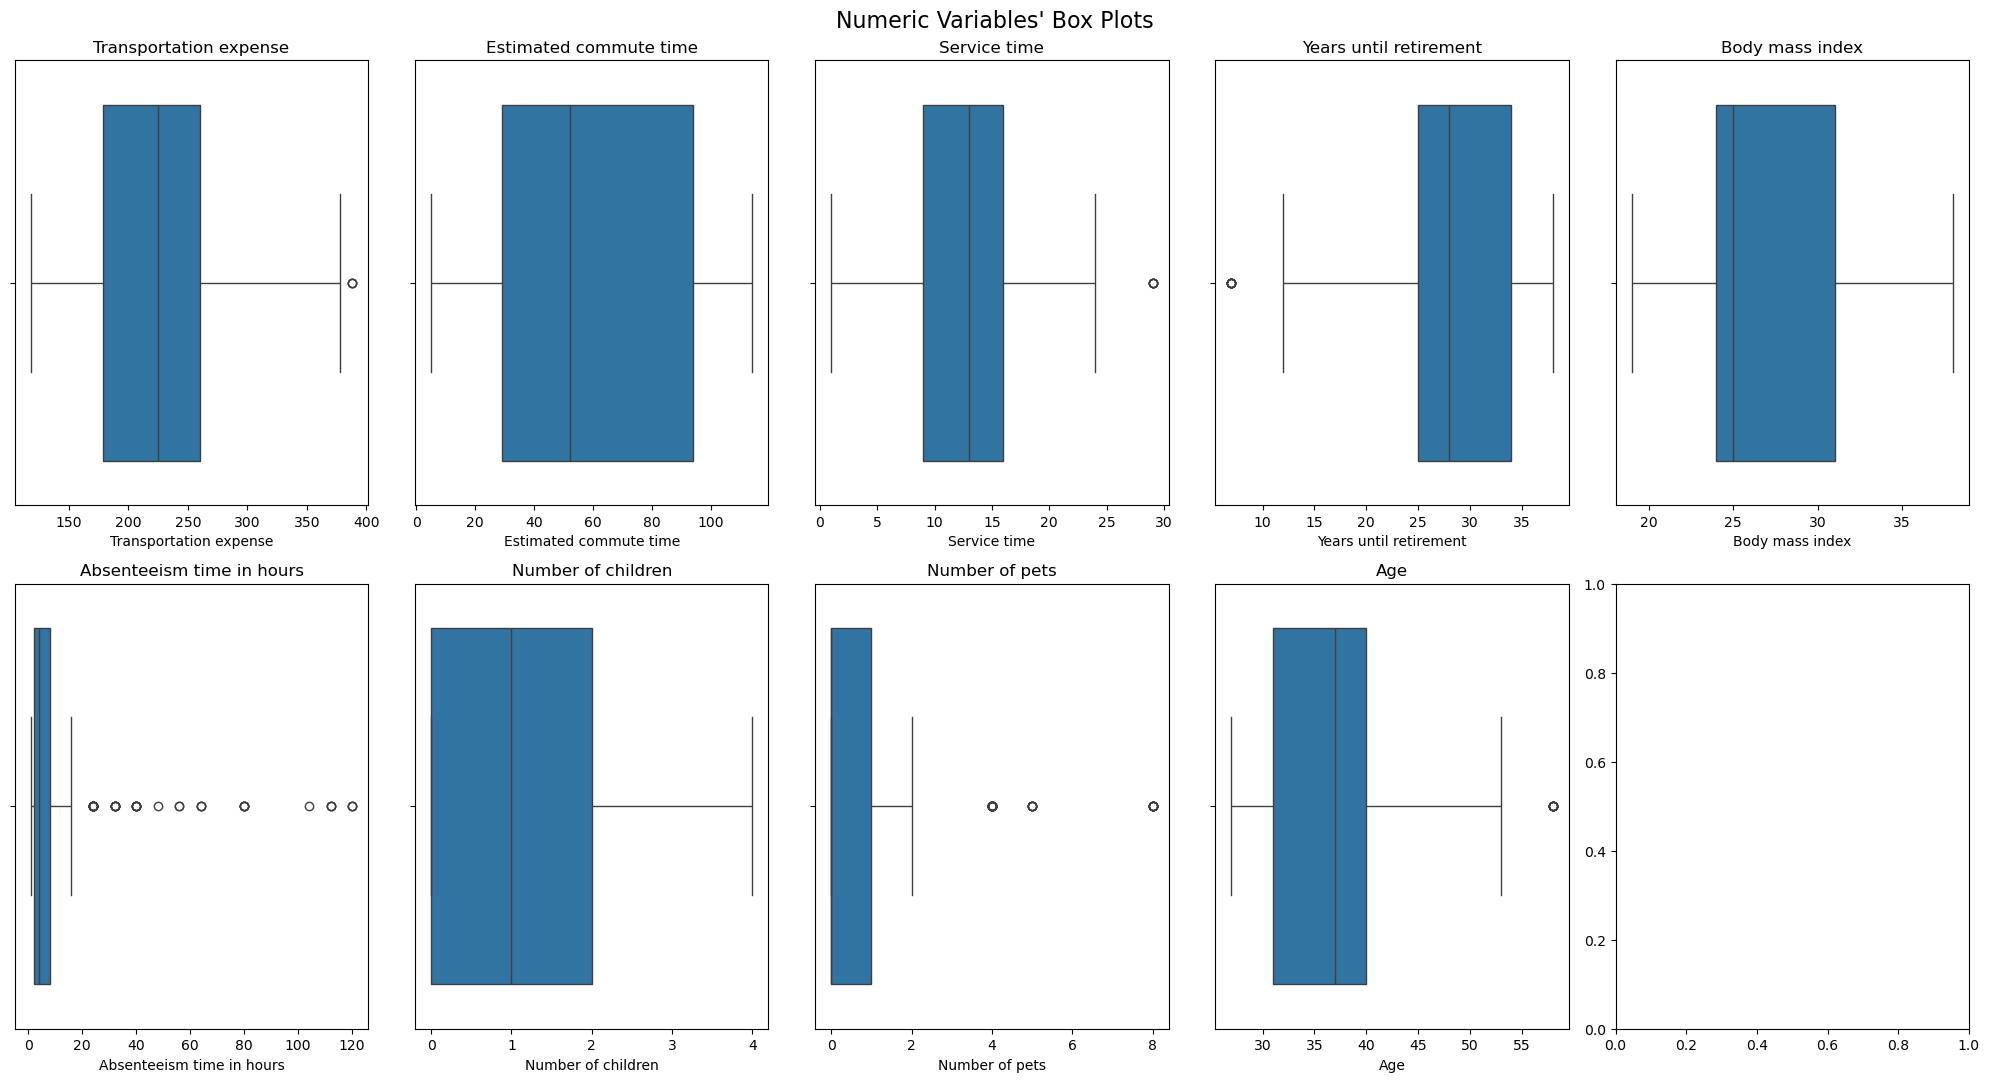

In [127]:
fig, axes = plt.subplots(2, ceil(len(numeric_cols) / 2), figsize=(20, 11))


for ax, feat in zip(axes.flatten(), numeric_cols):
    sns.boxplot(x=absent[feat].dropna(), ax=ax)
    ax.set_title(feat)


plt.suptitle("Numeric Variables' Box Plots", fontsize=16)

plt.tight_layout()
plt.show()


<b>2.3.2 Handling outliers</b>

<u>Transportation Expense — Winsorization</u>

In [128]:

col = absent['Transportation expense'].copy()

# Winsorize the top 1% of Transportation Expense to reduce influence of extreme values
col_wins = winsorize(col, limits=[0, 0.01]) 

absent['Transportation expense'] = col_wins


"Transportation expense" contained a few extremely high values. We applied winsorization at 1%, limiting the top 1% to reduce their influence while preserving the majority of data.

<u>Number of Pets — upper cap</u>

In [129]:
absent['Number of pets'] = absent['Number of pets'].clip(upper=4)

"Number of pets" were clipped to 4 to maintain consistency with the typical range of employees.

<u>Absenteeism time in hours — upper</u>

In [130]:
absent['Absenteeism time in hours'] = absent['Absenteeism time in hours'].clip(upper=40)

"Absenteeism time" in hours contained some unrealistical high values. We capped these at 40 hours, ensuring that the variable reflects plausible workweek absences without distorting analyses.

<font color='#006699' size=6>3. Encoding Categorical Variables</font> <a class="anchor" id="p3"></a>
  
[Back to TOC](#toc)

Before clustering, categorical variables must be represented numerically because most clustering algorithms rely on distance calculations. We decided to transform the binary column, 'Disciplinary failure', of 'Yes/No' to '1/0'. 

In [131]:
# To prepare for clustering, we must convert them into numeric format.
# Disciplinary failure is binary ('Yes'/'No'), so we map it directly to 0/1.
absent['Disciplinary failure'] = absent['Disciplinary failure'].map({
    'Yes': 1,
    'No': 0
})

In [132]:
absent.to_csv("absent_preprocessed.csv", index=False)